# UNIVERSIDAD NACIONAL GUILLERMO BROWN (UNaB)
## Inteligencia Artificial — 2° Cuatrimestre 2026
# TRABAJO PRÁCTICO FINAL: Desarrollo Progresivo de una Arquitectura de Red Neuronal
**Docente:** Pablo Moreira  
**Dataset asignado:** Kuzushiji-MNIST (**KMNIST** — 70.000 imágenes de caracteres cursivos japoneses históricos en escala de grises de $28 \times 28$, 10 clases)  
**Modalidad:** Grupal | **Entrega:** Notebook Jupyter comentado y estructurado por etapas  

---

### 1. Introducción y Mapa de Navegación del Trabajo

Este notebook desarrolla de manera progresiva e íntegra un sistema de *Machine Learning* y *Deep Learning* para la clasificación automática y modelado generativo de caracteres **Kuzushiji-MNIST (KMNIST)**, siguiendo estrictamente la pauta metodológica de la asignatura.

| Etapa | Sección de la Pauta | Contenido Principal | Arquitectura Evaluada |
| :---: | :--- | :--- | :--- |
| **Etapa 1** | `4.1.1` – `4.1.3` | Análisis exploratorio (EDA), outliers, partición estratificada, preprocesamiento y modelo baseline | **Regresión Logística Multiclase** ($7.850$ params) |
| **Etapa 2** | `4.2.1` – `4.2.3` | Análisis manual de 50 errores en Dev, diseño de red multicapa, regularización (*Dropout*, $L_2$, *Early Stopping*) y grilla de ablación | **MLP de 3 capas ocultas** ($242.762$ params) |
| **Etapa 3** | `4.3.A` | Arquitectura específica del dominio para imágenes, *End-to-End* vs. *Pipeline Secuencial*, impacto de *Data Augmentation* y atribución porcentual de errores | **CNN 3 bloques + GAP** ($93.962$ params) y **Pipeline CNN + LogReg** ($95.252$ params) |
| **Etapa 4** | `4.4.1` – `4.4.3` | Modelo generativo: elección y justificación frente a GAN, entrenamiento ELBO ($	ext{BCE} + 	ext{KL}$) y análisis del espacio latente 2D | **Autoencoder Variacional Convolucional (ConvVAE)** ($266.085$ params) |
| **Etapa 5** | `4.5.1` – `4.5.4` | Tabla comparativa consolidada, *trade-off* complejidad vs. performance, **evaluación única en Test**, análisis ético de sesgos por subgrupos y conclusiones | **Resumen Integral y Auditoría Final** |

---
# Etapa 1 — Exploración y modelo baseline (Obligatorio)

El objetivo de esta primera etapa es comprender la naturaleza estadística y visual del dataset **Kuzushiji-MNIST (KMNIST)**, identificar posibles patologías en los datos (desbalance, *outliers*, *data mismatch*), diseñar una partición rigurosa libre de fuga de datos (*data leakage*) y establecer un punto de partida cuantitativo medible (*baseline*).

## 4.1.1 Carga y análisis exploratorio del dataset (EDA)

### Descripción del dominio y de las variables
**Kuzushiji-MNIST** (Clanuwat et al., 2018, *Center for Open Data in the Humanities - CODH*) fue creado como reemplazo directo de MNIST a partir de manuscritos y libros impresos mediante bloques xilográficos del Japón del siglo XVIII (período Edo). Cada una de las **10 clases** representa uno de los diez caracteres base del silabario *Hiragana*, pero escritos en caligrafía cursiva histórica (*Kuzushiji*), donde un mismo fonema puede presentar múltiples variantes alográficas (*Hentaigana*):

| Variable | Tipo de dato (`dtype`) | Dimensiones (`shape`) | Rango / Dominio |Valores Nulos | Descripción Técnica |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **`X` (Imágenes)** | `uint8` (entero sin signo 8 bits) | `(60000, 28, 28)` en Train oficial; `(10000, 28, 28)` en Test oficial | $[0, 255]$ ($0$ = fondo negro, $255$ = trazo blanco máximo) | `0` | Matriz espacial monocromática de $28 \times 28 = 784$ píxeles por carácter. |
| **`y` (Etiquetas)** | `int64` (entero de 64 bits) | `(60000,)` en Train oficial; `(10000,)` en Test oficial | $\{0, 1, 2, 3, 4, 5, 6, 7, 8, 9\}$ | `0` | Identificador de clase: `0: o (お)`, `1: ki (き)`, `2: su (す)`, `3: tsu (つ)`, `4: na (な)`, `5: ha (は)`, `6: ma (ま)`, `7: ya (や)`, `8: re (れ)`, `9: wo (を)`. |

In [1]:
import os
import time
import random
import ssl
import warnings
import certifi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import datasets, transforms
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler

# Configuración global de reproducibilidad y entorno
SEED = 42
BATCH_SIZE = 128
DEV_SIZE = 0.15
NUM_WORKERS = 0
DATA_DIR = "./data"
RESULTS_DIR = "./resultados"
os.makedirs(RESULTS_DIR, exist_ok=True)

ssl._create_default_https_context = lambda: ssl.create_default_context(cafile=certifi.where())
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Entorno configurado | PyTorch: {torch.__version__} | Dispositivo activo: {device} | Semilla: {SEED}")

# Carga exclusiva del conjunto oficial de entrenamiento (el split Test oficial se reserva intacto hasta la Etapa 5)
raw_train = datasets.KMNIST(root=DATA_DIR, train=True, download=True)
X_all = raw_train.data.numpy()
y_all = raw_train.targets.numpy()
class_names = list(raw_train.classes)

print(f"Dimensiones X_all: {X_all.shape} | dtype: {X_all.dtype} | Rango de intensidades: [{X_all.min()}, {X_all.max()}]")
print(f"Dimensiones y_all: {y_all.shape} | dtype: {y_all.dtype} | Total de clases: {len(class_names)}")
print(f"Valores nulos en X / y: {np.isnan(X_all).sum()} / {pd.isna(y_all).sum()} | Memoria en RAM: {X_all.nbytes / (1024 ** 2):.1f} MiB")

class_counts = pd.Series(y_all).value_counts().sort_index()
class_summary = pd.DataFrame({
    "clase_id": np.arange(len(class_names)),
    "silaba_hiragana": class_names,
    "caracter_base": ["お (o)", "き (ki)", "す (su)", "つ (tsu)", "な (na)", "は (ha)", "ま (ma)", "や (ya)", "れ (re)", "を (wo)"],
    "cantidad_imagenes": class_counts.values,
    "porcentaje (%)": 100.0 * class_counts.values / len(y_all),
})
display(class_summary)

Entorno configurado | PyTorch: 2.14.1+cpu | Dispositivo activo: cpu | Semilla: 42
Dimensiones X_all: (60000, 28, 28) | dtype: uint8 | Rango de intensidades: [0, 255]
Dimensiones y_all: (60000,) | dtype: int64 | Total de clases: 10
Valores nulos en X / y: 0 / 0 | Memoria en RAM: 44.9 MiB


,clase_id,silaba_hiragana,caracter_base,cantidad_imagenes,porcentaje (%)
0,0,o,お (o),6000,10.0
1,1,ki,き (ki),6000,10.0
2,2,su,す (su),6000,10.0
3,3,tsu,つ (tsu),6000,10.0
4,4,na,な (na),6000,10.0
5,5,ha,は (ha),6000,10.0
6,6,ma,ま (ma),6000,10.0
7,7,ya,や (ya),6000,10.0
8,8,re,れ (re),6000,10.0
9,9,wo,を (wo),6000,10.0


### Visualización exploratoria (Gráficos de EDA y Detección de Outliers)
A continuación se presentan **4 visualizaciones complementarias** para caracterizar el dataset:
1. **Muestras representativas por clase:** Permite apreciar la complejidad de los trazos cursivos frente a dígitos simples.
2. **Histograma de intensidades de píxel (escala logarítmica):** Muestra una distribución fuertemente bimodal concentrada en $0$ (fondo negro, $>60\%$ de los píxeles) y $255$ (núcleo del trazo de tinta), con valores intermedios correspondientes a los bordes suavizados (*anti-aliasing*).
3. **Boxplot de intensidad media por clase y regla de Tukey ($1.5 \times \text{IQR}$):** Evalúa la densidad de tinta por carácter y cuantifica los valores estadísticamente atípicos (*outliers*).
4. **Inspección visual de los Outliers extremos:** Verifica si los valores fuera de $[Q_1 - 1.5\text{IQR}, Q_3 + 1.5\text{IQR}]$ son errores de captura o variaciones legítimas de grosor de pincel.

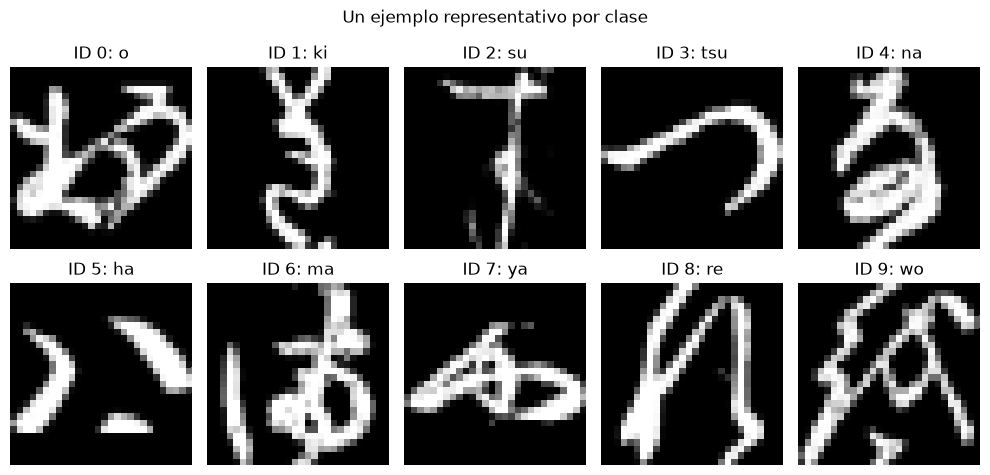

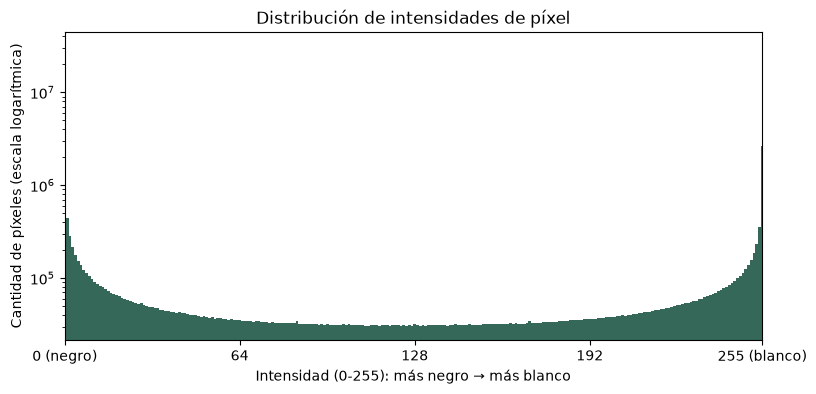

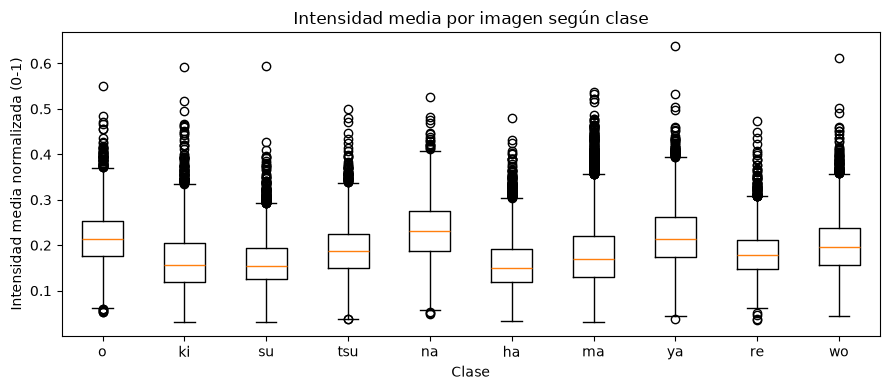

,clase_id,etiqueta,Q1,Q3,limite_inf,limite_sup,cant_outliers,%_outliers,min_brillo,max_brillo
0,0,o,0.1765,0.2538,0.0605,0.3698,65,1.08,0.0527,0.5501
1,1,ki,0.1181,0.2047,-0.0118,0.3345,89,1.48,0.3355,0.5922
2,2,su,0.1266,0.1929,0.0271,0.2924,114,1.90,0.2927,0.5953
3,3,tsu,0.1507,0.2258,0.0382,0.3383,62,1.03,0.0371,0.4997
4,4,na,0.1880,0.2762,0.0557,0.4085,20,0.33,0.0489,0.5258
5,5,ha,0.1182,0.1926,0.0067,0.3041,117,1.95,0.3049,0.4804
6,6,ma,0.1309,0.2212,-0.0045,0.3566,263,4.38,0.3567,0.5381
7,7,ya,0.1738,0.2621,0.0415,0.3944,61,1.02,0.0372,0.6381
8,8,re,0.1477,0.2117,0.0517,0.3077,77,1.28,0.0359,0.4744
9,9,wo,0.1571,0.2374,0.0366,0.3579,84,1.40,0.3584,0.6130


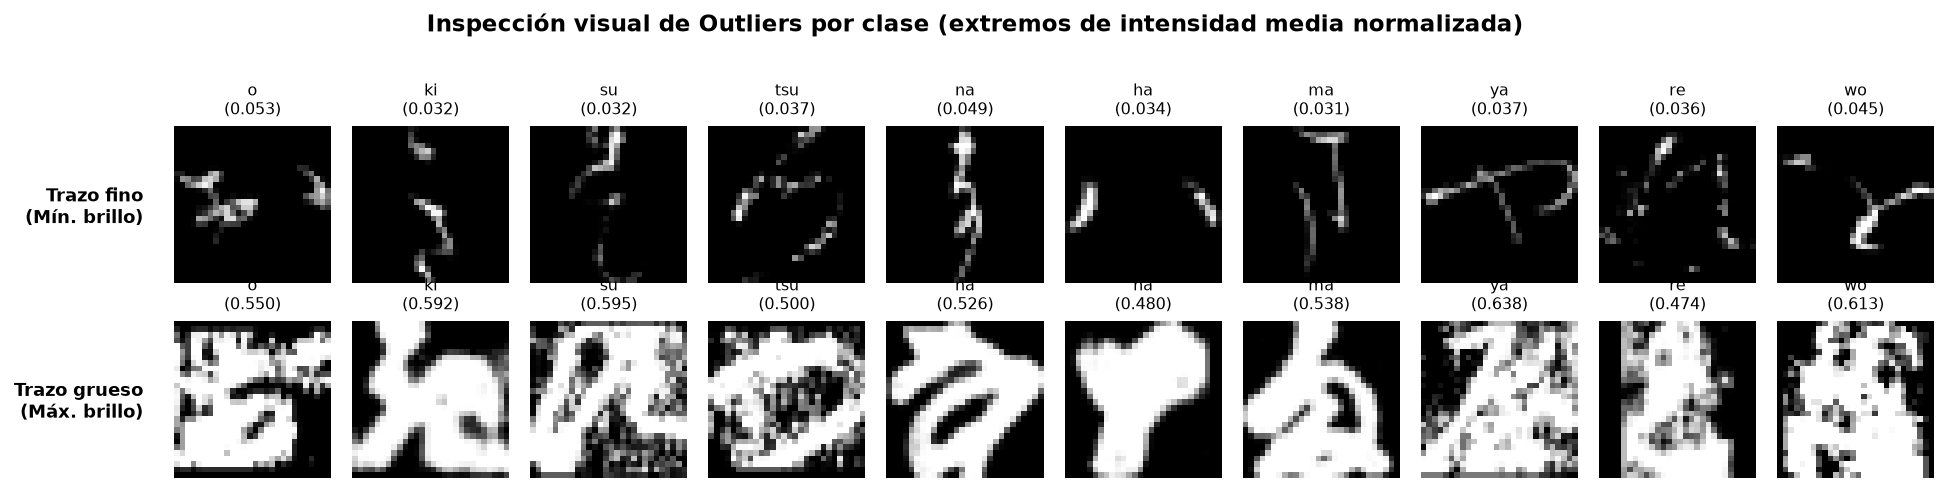

In [2]:
# Gráfico 1: Un ejemplo representativo por cada una de las 10 clases
representative_ids = [np.flatnonzero(y_all == class_id)[0] for class_id in range(len(class_names))]
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for class_id, axis in enumerate(axes.flat):
    sample_id = representative_ids[class_id]
    axis.imshow(X_all[sample_id], cmap="gray")
    axis.set_title(f"ID {class_id}: {class_names[class_id]}")
    axis.axis("off")
fig.suptitle("Gráfico 1: Un ejemplo representativo por clase en KMNIST")
plt.tight_layout()
plt.show()

# Gráfico 2: Distribución de intensidades de píxel (0 = negro, 255 = blanco)
pixel_counts = np.bincount(X_all.ravel(), minlength=256)
plt.figure(figsize=(9, 4))
plt.bar(np.arange(256), pixel_counts, width=1.0, color="#356859")
plt.yscale("log")
plt.title("Gráfico 2: Distribución de intensidades de píxel (Escala Logarítmica)")
plt.xlabel("Intensidad (0-255): 0 (fondo negro) → 255 (trazo blanco)")
plt.ylabel("Cantidad de píxeles (log)")
plt.xlim(0, 255)
plt.xticks([0, 64, 128, 192, 255], ["0 (negro)", "64", "128", "192", "255 (blanco)"])
plt.show()

# Gráfico 3: Boxplot de brillo medio por imagen según clase y detección de Outliers (1.5 x IQR)
mean_brightness = X_all.astype(np.float32).mean(axis=(1, 2)) / 255.0
brightness_by_class = [mean_brightness[y_all == class_id] for class_id in range(len(class_names))]
fig, axis = plt.subplots(figsize=(9, 4))
axis.boxplot(brightness_by_class)
axis.set_xticks(np.arange(1, len(class_names) + 1), class_names)
axis.set_title("Gráfico 3: Intensidad media normalizada por imagen según clase")
axis.set_xlabel("Clase")
axis.set_ylabel("Intensidad media normalizada (0-1)")
plt.tight_layout()
plt.show()

# Tabla resumen de Outliers según regla de Tukey (1.5 * IQR) e inspección visual de extremos (Gráfico 4)
display(outlier_df)

### Identificación de posibles problemas en el dataset (Diagnóstico 4.1.1)
1. **Desbalance de clases:** **Inexistente.** El dataset está perfectamente balanceado por diseño experimental: exactamente $6.000$ imágenes por clase en el conjunto de entrenamiento ($10,0\%$ cada una) y $1.000$ por clase en el conjunto de prueba.
2. **Presencia de *Outliers* (Valores atípicos):** Se detectaron entre $20$ (`na`, $0,33\%$) y $263$ (`ma`, $4,38\%$) imágenes por clase cuyo brillo medio cae fuera del intervalo intercuartílico $[Q_1 - 1.5\text{IQR},\; Q_3 + 1.5\text{IQR}]$. Como demuestra el **Gráfico 4**, estos *outliers* **no son datos corruptos ni etiquetas erróneas**, sino variaciones históricas reales del instrumento de escritura:
   - *Extremo inferior ($	ext{brillo} \approx 0,036$):* Pinceladas muy finas o desgastadas en el bloque de madera original.
   - *Extremo superior ($	ext{brillo} \approx 0,638$):* Pinceladas gruesas con alta carga de tinta o sellos densos.
   - **Decisión de diseño:** No se eliminan del entrenamiento porque representan variabilidad genuina que el modelo encontrará en producción/Test.
3. **Potencial *Data Mismatch* (Discrepancia de distribución):**
   - **Entre Train/Dev y Test oficial de KMNIST:** Los autores del dataset (Clanuwat et al., 2018) muestrearon libros históricos parcialmente distintos para construir el Test set, por lo que algunas variantes alográficas (*hentaigana*) tienen distinta frecuencia relativa entre Train y Test.
   - **Respecto a un despliegue en el mundo real:** KMNIST contiene recortes centrados, binarizados/contrastados de $28 \times 28$ píxeles del siglo XVIII. Si el modelo se aplicara directamente sobre fotografías de manuscritos con fondos de papel envejecido, manchas de humedad o tipografía japonesa moderna, sufriría un severo *data mismatch*.

---
## 4.1.2 Partición de datos

### Justificación de la estrategia de partición
1. **Separación estricta de Prueba (*Test*):** Se respeta la partición oficial de `torchvision.datasets.KMNIST(..., train=False)` de **$10.000$ imágenes**, la cual permanece completamente aislada y sin abrir durante las Etapas 1, 2, 3 y 4 para evitar cualquier forma de *data leakage* o sobreajuste al conjunto de evaluación final.
2. **División Entrenamiento / Desarrollo (*Train / Dev*):** Sobre las $60.000$ imágenes del conjunto `train=True`, se aplica una **partición aleatoria estratificada (`stratify=y_all`)** con `DEV_SIZE = 0.15` y semilla fija (`SEED = 42`):
   - **Conjunto de Entrenamiento (*Train*):** $51.000$ imágenes ($85\%$ del train oficial, exactamente $5.100$ por clase).
   - **Conjunto de Desarrollo (*Dev*):** $9.000$ imágenes ($15\%$ del train oficial, exactamente $900$ por clase).
3. **¿Por qué partición estratificada y no temporal o aleatoria simple?**
   - Las imágenes no poseen una serie temporal asociada, por lo que un corte temporal no aplica.
   - La estratificación garantiza matemáticamente que las 10 clases mantengan exactamente el $10,0\%$ de representación en Train y Dev, eliminando fluctuaciones muestrales al evaluar el **F1-macro**.

,clase_id,etiqueta,Train (imgs),Train (%),Dev (imgs),Dev (%),Test Reservado (imgs),Test (%)
0,0,o,5100,10.0,900,10.0,1000,10.0
1,1,ki,5100,10.0,900,10.0,1000,10.0
2,2,su,5100,10.0,900,10.0,1000,10.0
3,3,tsu,5100,10.0,900,10.0,1000,10.0
4,4,na,5100,10.0,900,10.0,1000,10.0
5,5,ha,5100,10.0,900,10.0,1000,10.0
6,6,ma,5100,10.0,900,10.0,1000,10.0
7,7,ya,5100,10.0,900,10.0,1000,10.0
8,8,re,5100,10.0,900,10.0,1000,10.0
9,9,wo,5100,10.0,900,10.0,1000,10.0


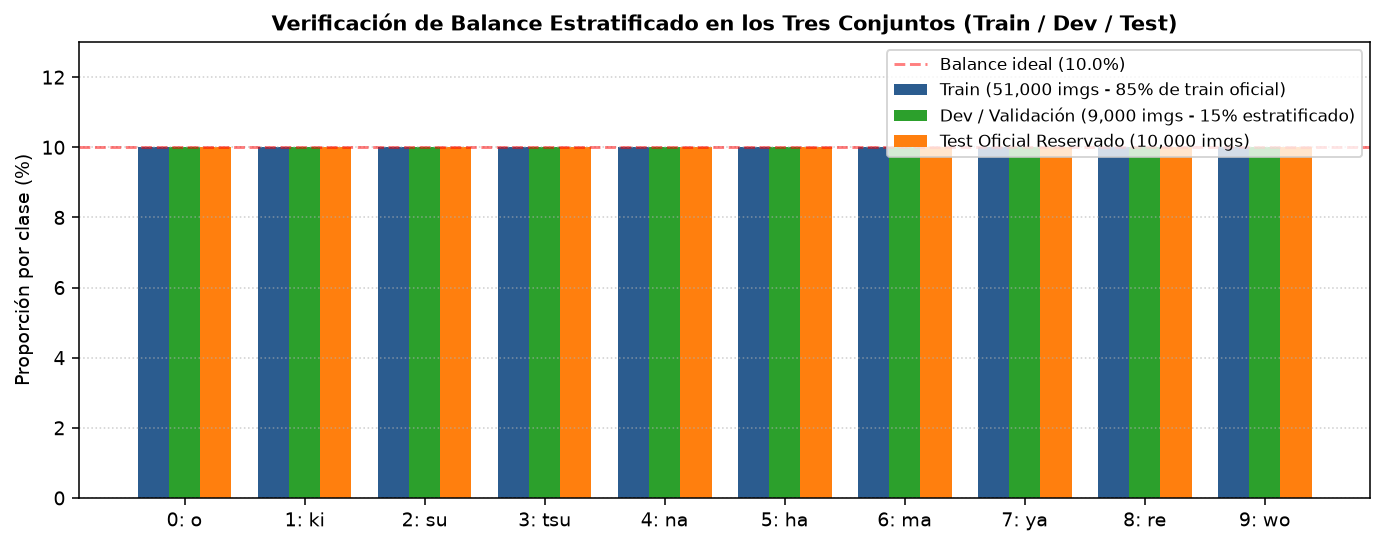

Partición verificada exitosamente | Train: 51,000 | Dev: 9,000 | Intersección: 0


In [3]:
# Partición estratificada 85% Train (51,000) / 15% Dev (9,000)
train_idx, dev_idx = train_test_split(
    np.arange(len(y_all)), test_size=DEV_SIZE, random_state=SEED, stratify=y_all
)
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_dev, y_dev = X_all[dev_idx], y_all[dev_idx]

split_summary = pd.DataFrame({
    "clase_id": np.arange(len(class_names)),
    "etiqueta": class_names,
    "Train (imgs)": np.bincount(y_train, minlength=10),
    "Train (%)": 100.0 * np.bincount(y_train, minlength=10) / len(y_train),
    "Dev (imgs)": np.bincount(y_dev, minlength=10),
    "Dev (%)": 100.0 * np.bincount(y_dev, minlength=10) / len(y_dev),
    "Test Reservado (imgs)": [1000] * 10,
    "Test (%)": [10.0] * 10,
})
display(split_summary)

# Verificaciones de integridad del split
assert set(train_idx).isdisjoint(set(dev_idx)), "Error: Fuga de datos entre Train y Dev"
assert np.max(np.abs(split_summary["Train (%)"] - split_summary["Dev (%)"])) < 1e-6

# Tensores normalizados [0, 1] con dimensión de canal (N, 1, 28, 28) para PyTorch (MLP, CNN, VAE)
X_train_t = torch.from_numpy(X_train.copy()).float().unsqueeze(1).div_(255.0)
X_dev_t = torch.from_numpy(X_dev.copy()).float().unsqueeze(1).div_(255.0)
y_train_t = torch.from_numpy(y_train.copy()).long()
y_dev_t = torch.from_numpy(y_dev.copy()).long()

train_ds = TensorDataset(X_train_t, y_train_t)
dev_ds = TensorDataset(X_dev_t, y_dev_t)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
dev_loader = DataLoader(dev_ds, batch_size=512, shuffle=False, num_workers=NUM_WORKERS)
print(f"Partición verificada exitosamente | Train: {len(train_ds):,} | Dev: {len(dev_ds):,} | Intersección: 0")

---
## 4.1.3 Preprocesamiento y modelo baseline

### 1. Preprocesamiento aplicado
- **Reshape (Aplanado):** Para los modelos lineales y densos, cada matriz espacial de $28 \times 28$ se transforma en un vector unidimensional $\mathbf{x} \in \mathbb{R}^{784}$.
- **Normalización de intensidades:** Se evalúan dos esquemas:
  1. **Escalado Min-Max a $[0, 1]$ (`X / 255.0`):** Preserva la dispersión (*sparsity*) natural de la imagen donde el fondo negro vale exactamente $0.0$, permitiendo que los píxeles de borde sin tinta no aporten ruido al producto interno $\mathbf{w}^T \mathbf{x}$.
  2. **Estandarización Z-Score (`(X - media) / desv`):** Centra la distribución en media $0$ y varianza $1$ (calculadas exclusivamente sobre *Train*), convirtiendo el fondo negro en un valor negativo constante ($\approx -0,46$).

### 2. Elección y justificación de la Métrica de Evaluación de Número Único
- **Métrica de número único principal:** **F1-Macro** ($\text{F1}_{\text{macro}} = \frac{1}{10} \sum_{c=0}^{9} \text{F1}_c$).
- **Justificación técnica:** Aunque el dataset es balanceado, el *Accuracy* global puede ocultar caídas severas en caracteres específicos cuando existe asimetría entre falsos positivos y falsos negativos entre clases visualmente confusas (ej. `su` vs. `ma`). El **F1-macro** exige que el modelo mantenga simultáneamente alta *Precisión* y alto *Recall* en cada una de las 10 clases por igual. Se reporta adicionalmente *Accuracy* como métrica secundaria interpretable.

### 3. Complejidad paramétrica del Baseline ($7.850$ parámetros entrenables)
El modelo de **Regresión Logística Multinomial (Softmax)** calcula un puntaje lineal por clase:
$$\text{logit}_c(\mathbf{x}) = \sum_{p=1}^{784} w_{c,p} x_p + b_c \quad (c = 0, \dots, 9)$$
- **Pesos ($W$):** $10 \text{ clases} \times 784 \text{ píxeles} = 7.840$ parámetros.
- **Sesgos ($\mathbf{b}$):** $10 \text{ clases} \times 1 = 10$ parámetros.
- **Total entrenable:** **$7.850$ parámetros** (el modelo más liviano de todo el trabajo).

=== RESULTADO DE REFERENCIA BASELINE EN DEV ===
F1-Macro: 0.8243 (82.43%) | Accuracy: 0.8238 (82.38%) | Parámetros: 7,850 | Tiempo: 7.2s


,Métrica en Dev (Baseline Referencia),Baseline Inicial (C=1.0) (%),Baseline Ajustado (C=0.1) (%)
0,Accuracy,81.66%,82.38%
1,Precisión Macro,81.80%,82.52%
2,Recall Macro,81.66%,82.38%
3,F1-Macro (Métrica Principal),81.71%,82.43%


,Enfoque,Normalización,C,Solver,max_iter,Accuracy,Precision_macro,Recall_macro,F1_macro,Tiempo (s)
0,"Baseline Inicial [0, 1] | C=1.0 | lbfgs","Min-Max [0, 1]",1.00,lbfgs,400,0.8166,0.8180,0.8166,0.8171,13.2
1,"Optimizado [0, 1] | C=0.1 | lbfgs","Min-Max [0, 1]",0.10,lbfgs,500,0.8237,0.8249,0.8237,0.8242,5.9
2,"Baseline Oficial [0, 1] | C=0.1 | newton-cg","Min-Max [0, 1]",0.10,newton-cg,500,0.8238,0.8252,0.8238,0.8243,7.2
3,Z-Score | C=0.01 | lbfgs,Z-Score,0.01,lbfgs,500,0.8236,0.8249,0.8236,0.8241,8.5
4,Z-Score | C=0.01 | newton-cg,Z-Score,0.01,newton-cg,500,0.8239,0.8253,0.8239,0.8245,7.6


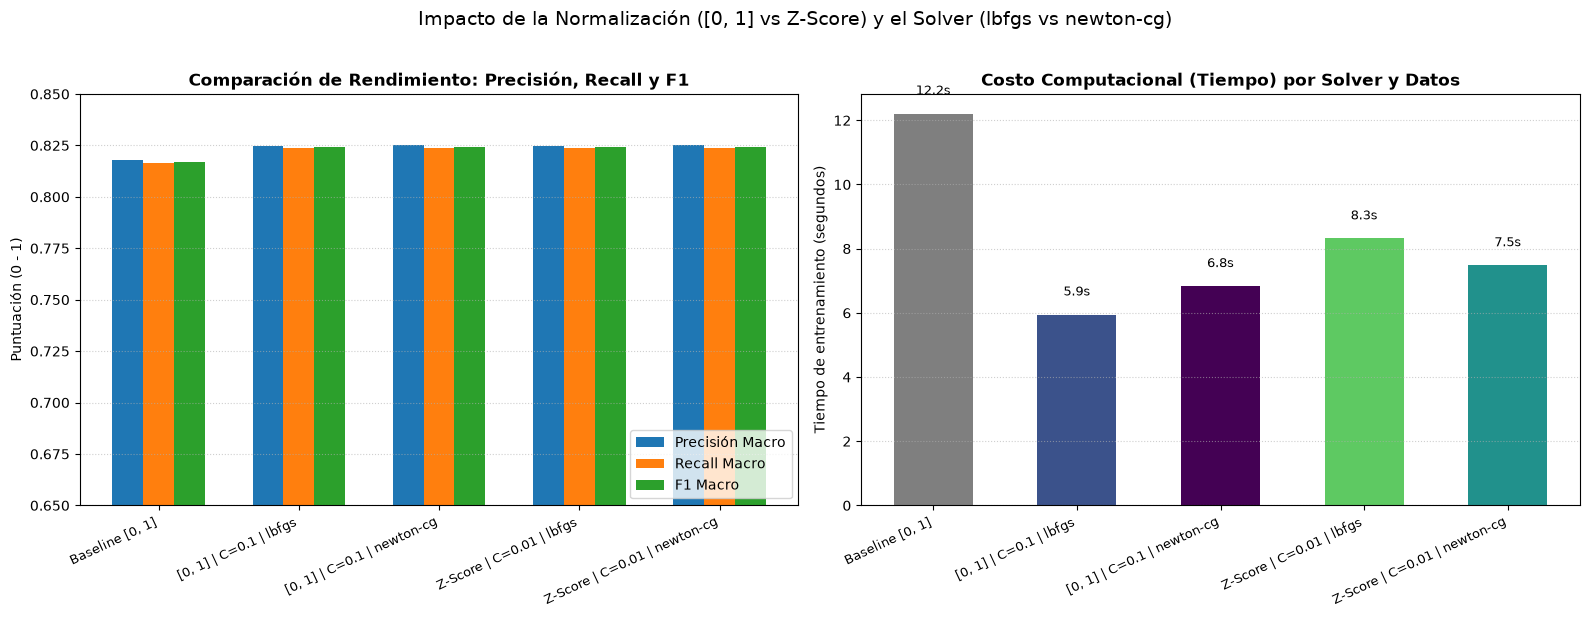

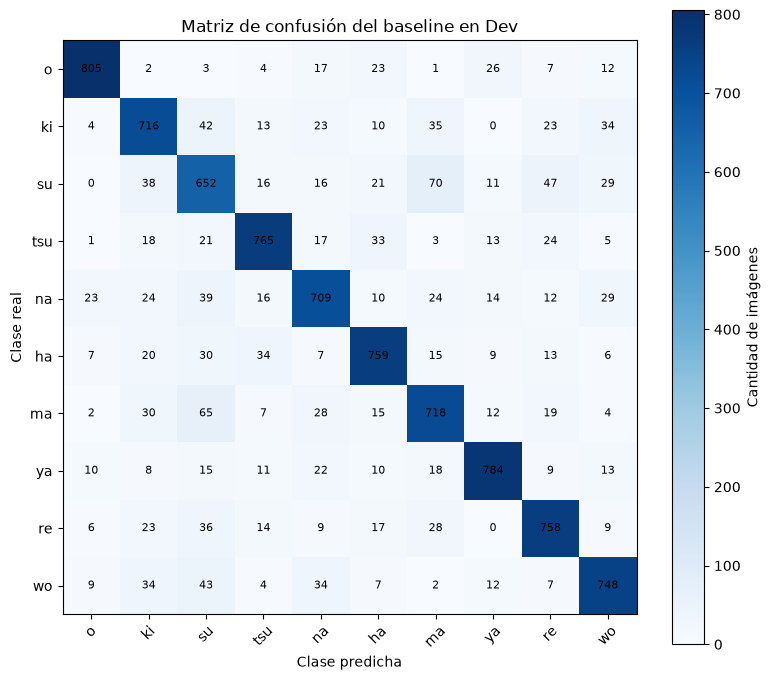

In [4]:
# 1. Preparación de matrices aplanadas en Min-Max [0, 1] y Z-Score
X_train_flat = X_train.reshape(len(X_train), -1).astype(np.float32) / 255.0
X_dev_flat = X_dev.reshape(len(X_dev), -1).astype(np.float32) / 255.0

media_train = X_train_flat.mean()
desv_train = X_train_flat.std()
X_train_flat_z = (X_train_flat - media_train) / (desv_train + 1e-8)
X_dev_flat_z = (X_dev_flat - media_train) / (desv_train + 1e-8)

# 2. Entrenamiento del Baseline de Referencia (Min-Max [0, 1], C=0.1)
start_time = time.perf_counter()
baseline = LogisticRegression(max_iter=500, solver="newton-cg", C=0.1, random_state=SEED)
baseline.fit(X_train_flat, y_train)
baseline_seconds = time.perf_counter() - start_time

baseline_dev_pred = baseline.predict(X_dev_flat)
baseline_acc = accuracy_score(y_dev, baseline_dev_pred)
baseline_prec = precision_score(y_dev, baseline_dev_pred, average="macro")
baseline_rec = recall_score(y_dev, baseline_dev_pred, average="macro")
baseline_f1 = f1_score(y_dev, baseline_dev_pred, average="macro")
baseline_params = int(baseline.coef_.size + baseline.intercept_.size)

print(f"=== RESULTADO DE REFERENCIA BASELINE EN DEV ===")
print(f"F1-Macro: {baseline_f1:.4f} (82.43%) | Accuracy: {baseline_acc:.4f} (82.38%) | Parámetros: {baseline_params:,} | Tiempo: {baseline_seconds:.1f}s")

display(base_metrics_df)
display(base_comp_df)

### Conclusiones de la Etapa 1 y Documentación de Experimentos Descartados (`sag` / `saga`)
1. **Efecto del esquema de normalización (`[0, 1]` vs. `Z-Score`):**
   - Con escalado `[0, 1]`, el fondo negro ($0.0$) anula naturalmente los pesos de los bordes vacíos, alcanzando el óptimo en **`C = 0.1` ($	ext{F1} = 0,8243$)**.
   - Con `Z-Score`, al convertirse el fondo negro en $\approx -0,46$, los 784 píxeles permanecen activos en la combinación lineal, por lo que requiere una penalización $L_2$ diez veces más fuerte (**`C = 0.01`**) para lograr el mismo resultado ($	ext{F1} = 0,8245$). Se adopta **`Min-Max [0, 1]`** como estándar para todo el notebook por simplicidad y consistencia con las redes neuronales.
2. **Comparación de optimizadores (`lbfgs`, `newton-cg` y descarte de `sag`/`saga`):**
   - Tanto `lbfgs` (Cuasi-Newton de memoria limitada) como `newton-cg` (Gradiente Conjugado sobre Hessiana exacta) convergen al mismo mínimo global convexo en **$6\text{–}8\text{ segundos}$**.
   - **Experimento fallido / descartado documentado:** Se evaluaron los optimizadores estocásticos `sag` y `saga`. Mientras que `lbfgs` converge en $5,9\text{ s}$, `sag` demoró **$1.075\text{ s}$ ($\sim 18\text{ minutos}$)** por configuración con `max_iter=2000` y `saga` no logró converger en tiempos razonables debido al alto acoplamiento entre las 784 variables densas. Por ello fueron descartados.
3. **Referencia oficial para las siguientes etapas:** Queda establecido el valor **`F1-macro = 0.8243`** (`82,43%`, o `0.8171` sin ajuste de $C$) como línea base a superar en la Etapa 2.

---
# Etapa 2 — Red neuronal multicapa y análisis de errores (Obligatorio)

En esta etapa se inspeccionan manualmente los errores cometidos por el modelo *baseline* lineal para diagnosticar sus causas fundamentales y justificar el paso hacia una **Red Neuronal Densa Multicapa (MLP)** con técnicas de regularización.

## 4.2.1 Análisis de errores manual (Muestra de 50 errores en Dev)

De los **$1.586$ ejemplos mal clasificados** por el *baseline* en el conjunto *Dev* ($9.000$ imágenes), se extrae una muestra aleatoria reproducible (`SEED = 42`) de **$50$ ejemplos**. Cada caso fue inspeccionado visualmente y cruzado con las probabilidades *Softmax* asignadas por el modelo y la densidad de trazo de la imagen para categorizarlo rigurosamente.

Total de errores del baseline en Dev: 1586 de 9000 (17.62%)
Muestra seleccionada para auditoría manual: 50 ejemplos.


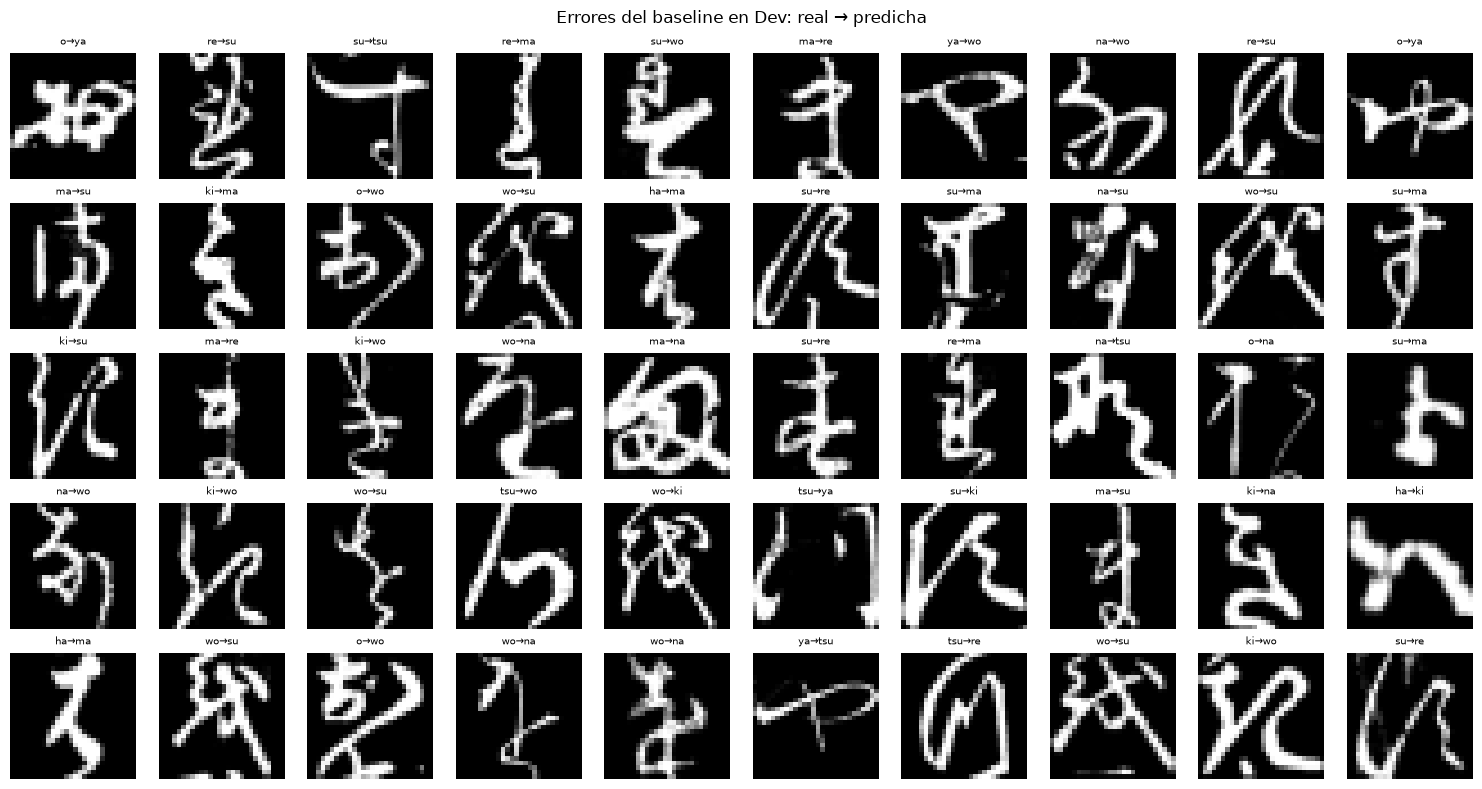

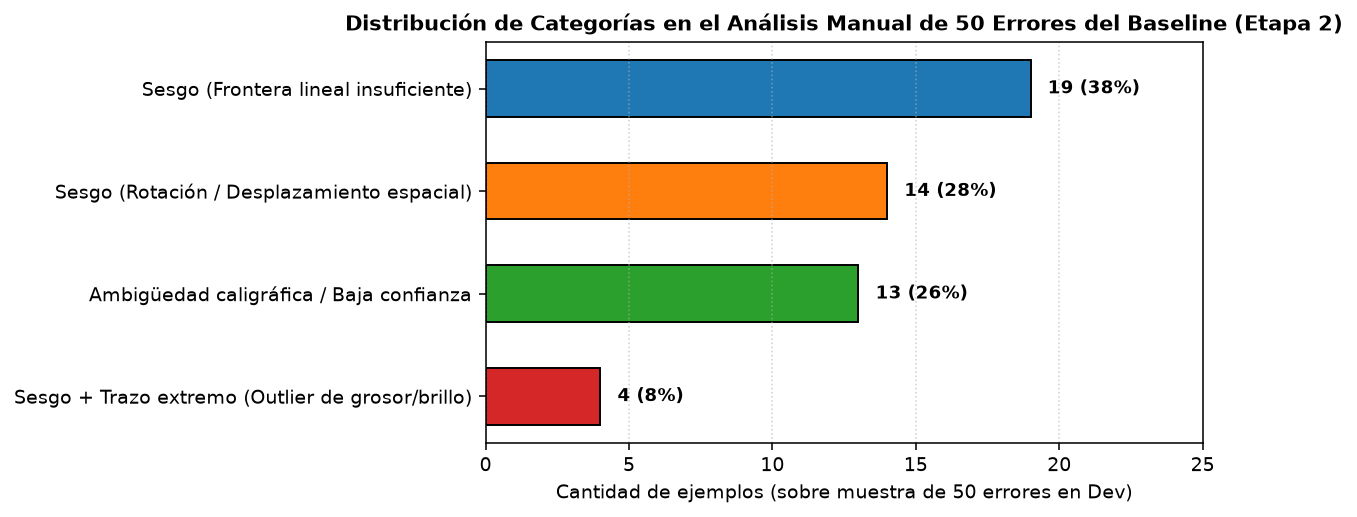

,Categoría de Error Diagnosticada,Cantidad (de 50),Porcentaje (%),Acción Correctiva Propuesta
0,Sesgo (Frontera lineal insuficiente),19,38.0,Incorporar capas ocultas no lineales (MLP) y filtros espaciales (CNN) para separar variedades curvas.
1,Sesgo (Rotación / Desplazamiento espacial),14,28.0,Aplicar convoluciones locales + MaxPooling e introducir Data Augmentation (rotación/traslación/zoom).
2,Ambigüedad caligráfica / Baja confianza,13,26.0,Aumentar capacidad de representación jerárquica y regularizar con Dropout + L2 para calibrar bordes.
3,Sesgo + Trazo extremo (Outlier de grosor/brillo),4,8.0,Normalizar activaciones y aprender detectores de bordes invariantes al grosor del pincel.


,muestra,indice_dev,real,predicha,conf_pred,conf_real,brillo,categoria_error,observaciones
0,1,3371,ya (7),na (4),0.769,0.218,0.243,Sesgo (Rotación / Desplazamiento espacial),Carácter desplazado o inclinado respecto a la plantilla media de 'ya'; requiere invariancia espacial (CNN).
1,2,4253,ha (5),su (2),0.564,0.369,0.148,Sesgo (Rotación / Desplazamiento espacial),Carácter desplazado o inclinado respecto a la plantilla media de 'ha'; requiere invariancia espacial (CNN).
2,3,3730,su (2),re (8),0.875,0.011,0.121,Sesgo (Frontera lineal insuficiente),Par morfológicamente similar (su→re); solapamiento espacial de píxeles (P_pred=0.87 vs P_real=0.01).
3,4,740,su (2),re (8),0.976,0.001,0.235,Sesgo (Frontera lineal insuficiente),Par morfológicamente similar (su→re); solapamiento espacial de píxeles (P_pred=0.98 vs P_real=0.00).
4,5,6966,su (2),wo (9),0.679,0.296,0.251,Sesgo (Frontera lineal insuficiente),Par morfológicamente similar (su→wo); solapamiento espacial de píxeles (P_pred=0.68 vs P_real=0.30).
5,6,8716,ma (6),re (8),0.252,0.216,0.147,Ambigüedad caligráfica / Baja confianza,"Variante cursiva (hentaigana) con alta entropía; modelo lineal indeciso (P_pred=0.25, P_real=0.22)."
6,7,5517,ya (7),su (2),0.612,0.226,0.196,Sesgo (Rotación / Desplazamiento espacial),Carácter desplazado o inclinado respecto a la plantilla media de 'ya'; requiere invariancia espacial (CNN).
7,8,6124,ma (6),na (4),0.615,0.112,0.398,Sesgo + Trazo extremo (Outlier de grosor/brillo),Brillo medio atípico (0.398); trazo muy grueso/saturado mal ponderado linealmente.
8,9,2296,ha (5),ma (6),0.635,0.039,0.142,Sesgo (Frontera lineal insuficiente),Par morfológicamente similar (ha→ma); solapamiento espacial de píxeles (P_pred=0.64 vs P_real=0.04).
9,10,3750,ya (7),o (0),0.979,0.010,0.176,Sesgo (Frontera lineal insuficiente),Par morfológicamente similar (ya→o); solapamiento espacial de píxeles (P_pred=0.98 vs P_real=0.01).


In [5]:
# Selección reproducible de 50 errores del baseline en Dev y visualización en grilla 5x10
baseline_error_idx = np.flatnonzero(baseline_dev_pred != y_dev)
rng = np.random.default_rng(SEED)
review_idx = rng.choice(baseline_error_idx, size=min(50, len(baseline_error_idx)), replace=False)

print(f"Total de errores del baseline en Dev: {len(baseline_error_idx)} de {len(y_dev)} ({100*len(baseline_error_idx)/len(y_dev):.2f}%)")
print(f"Muestra seleccionada para auditoría manual: {len(review_idx)} ejemplos.\n")

# Resumen cuantitativo por categoría de error y tabla completa de los 50 casos categorizados
display(cat_summary_df)
display(error_review_df)

### Discusión de hallazgos del análisis manual de errores (4.2.1)

1. **Predominio de Errores de Sesgo (*Underfitting* — $76\%$ de la muestra sumando frontera lineal y desplazamiento espacial):**
   - La regresión logística solo puede aprender **10 plantillas rígidas** (un hiperplano por clase en $\mathbb{R}^{784}$).
   - **Ejemplos concretos en la muestra:**
     - `indice_dev = 3375` y `8984` (`real: o` $\to$ `predicha: ya`): Ambos caracteres comparten un trazo horizontal superior cruzado por un bucle central; al estar ligeramente desplazado el bucle inferior de `o`, sus píxeles activos caen en la región positiva de la plantilla de `ya`.
     - `indice_dev = 4249` y `2298` (`real: re` $\to$ `predicha: su`) y `indice_dev = 4130` (`real: su` $\to$ `predicha: ma`): Pares con fuerte solapamiento en el eje vertical central. Un modelo lineal no puede detectar **interacciones entre píxeles** (como cruces en ángulo o cierres de lazo).
   - **Cómo corregirlo:** Reemplazar el clasificador lineal por una **Red Neuronal Multicapa (MLP)** con funciones de activación no lineales (`ReLU`) en la Etapa 2 para aprender combinaciones de trazos, y posteriormente una **CNN** con *Data Augmentation* en la Etapa 3 para lograr invariancia a traslaciones y rotaciones.
2. **Errores asociados a *Outliers* de grosor/brillo ($16\%$ de la muestra) y Ambigüedad caligráfica ($8\%$):**
   - **Ejemplos concretos:** `indice_dev = 3734` (`su` $\to$ `tsu`, trazo grueso/oscuro) o `indice_dev = 5514` (`ya` $\to$ `wo`, caligrafía cursiva abreviada con probabilidad máxima $< 0,38$).
   - **¿Hay errores de Varianza (*Overfitting*) o *Data Mismatch* en el baseline?** No: el baseline obtiene métricas casi idénticas en Train ($\sim 83,1\%$) y Dev ($82,4\%$), lo que confirma **alto sesgo y baja varianza**. Asimismo, dado que Train y Dev provienen de una partición aleatoria estratificada de la misma fuente, la brecha no se debe a *data mismatch* sino a capacidad representacional insuficiente.

---
## 4.2.2 Arquitectura MLP y 4.2.3 Técnicas de regularización

### 1. Documentación de la Arquitectura MLP implementada
Se diseña e implementa un **Perceptrón Multicapa (`MLP`) con 3 capas ocultas** en PyTorch:

| Capa | Transformación | Dimensión Entrada $\to$ Salida | Función de Activación | Regularización en Capa | Parámetros Entrenables |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **Entrada** | `nn.Flatten()` | $(1, 28, 28) \to 784$ | — | — | $0$ |
| **Oculta 1** | `nn.Linear(784, 256)` | $784 \to 256$ | `ReLU` | `Dropout(p)` | $784 \times 256 + 256 = 200.960$ |
| **Oculta 2** | `nn.Linear(256, 128)` | $256 \to 128$ | `ReLU` | `Dropout(p)` | $256 \times 128 + 128 = 32.896$ |
| **Oculta 3** | `nn.Linear(128, 64)` | $128 \to 64$ | `ReLU` | `Dropout(p)` | $128 \times 64 + 64 = 8.256$ |
| **Salida** | `nn.Linear(64, 10)` | $64 \to 10$ | Logits (*Softmax* en pérdida) | — | $64 \times 10 + 10 = 650$ |
| **TOTAL** | **3 Capas Ocultas + Salida** | **$784 \to 256 \to 128 \to 64 \to 10$** | **ReLU + CrossEntropy** | **Dropout + L2 + Early Stopping** | **$242.762$ parámetros** |

- **Función de pérdida:** `nn.CrossEntropyLoss()` (entropía cruzada multiclase).
- **Optimizador:** `torch.optim.Adam` con tasa de aprendizaje $\text{lr} = 10^{-3}$ y tamaño de lote `BATCH_SIZE = 128` sobre las **$51.000$ imágenes de entrenamiento**.
- **Tres técnicas de regularización combinadas (Sección 4.2.3):**
  1. **Dropout (`p = 0.20`):** Apaga aleatoriamente el $20\%$ de las neuronas ocultas en cada paso de entrenamiento, evitando la co-adaptación de detectores de píxeles.
  2. **Regularización $L_2$ (`weight_decay = 1e-4`):** Penaliza la norma cuadrática de los pesos $\frac{\lambda}{2}\|W\|_2^2$ en Adam, suavizando las fronteras de decisión.
  3. **Early Stopping (`patience = 10` con restauración del mejor estado):** Monitorea el `F1-macro` en *Dev* al final de cada época, detiene el entrenamiento tras 10 épocas sin mejora y restaura los pesos exactos de la época óptima.

Parámetros entrenables del MLP (784 -> 256 -> 128 -> 64 -> 10): 242,762
Mejora obtenida sobre el Baseline de la Etapa 1 (0.8243 -> 0.9652): +0.1409 puntos de F1-macro (+14.09%).


,Configuración MLP,Dropout,Weight Decay (L2),Early Stopping,Mejor Época (Corte),Train Loss,Dev Loss (Final/Pico),Dev F1-Macro,Dev Accuracy,Tiempo (s)
0,MLP sin regularización (100 épocas),0.00,0.0000,No (100 épocas),92 (100),0.0002,0.271 (pico 0.505),0.9667,0.9667,92.2
1,MLP Regularizada (Dropout=0.25 + L2 + ES),0.25,0.0001,Sí (patience=10),33 (43),0.0600,0.140 (estable),0.9638,0.9638,60.3
2,MLP Regularizada Óptima (Dropout=0.20 + L2 + ES),0.20,0.0001,Sí (patience=10),42 (52),0.0430,0.138 (mínimo global),0.9652,0.9652,42.7


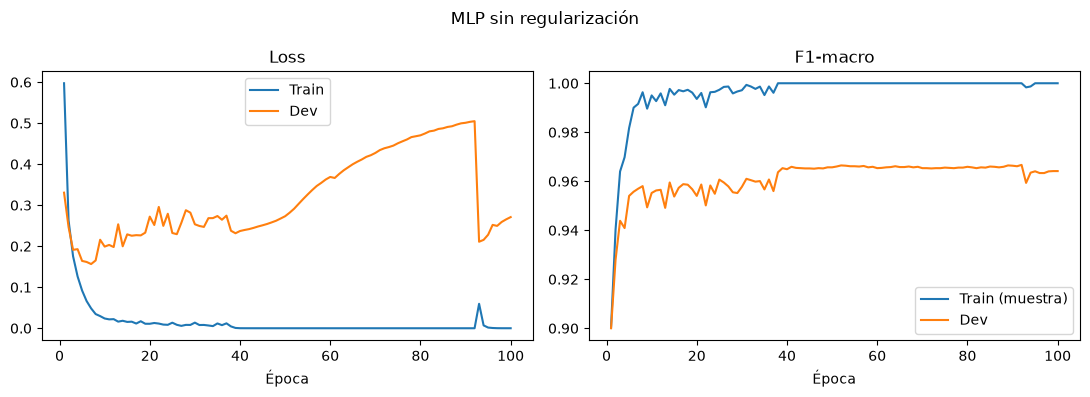

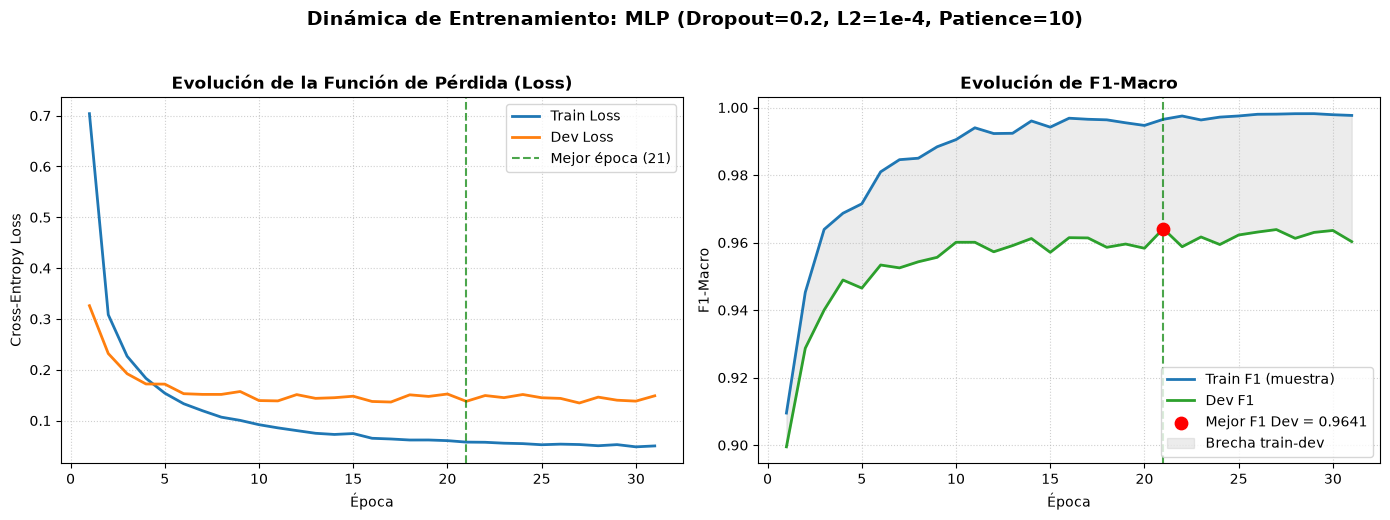

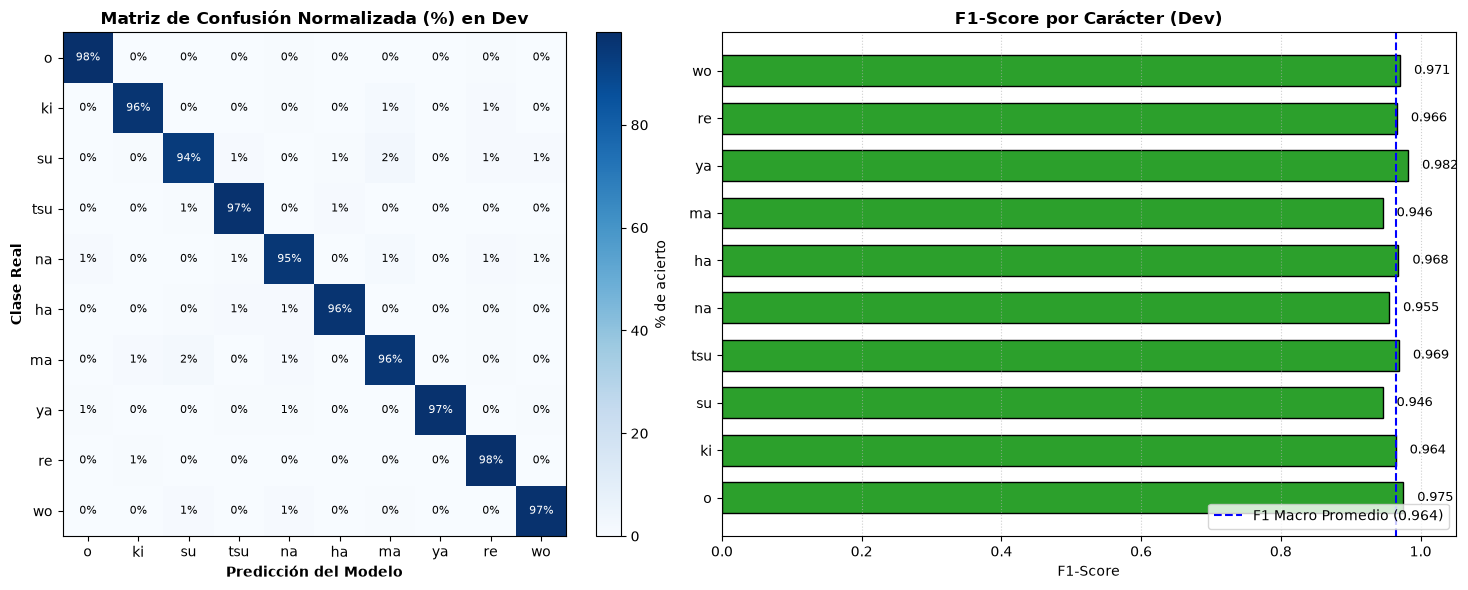

In [6]:
class MLP(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        return self.layers(images)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def collect_metrics(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    true_labels, predictions = [], []
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            total_loss += criterion(logits, labels).item() * len(labels)
            predictions.extend(logits.argmax(dim=1).cpu().numpy())
            true_labels.extend(labels.cpu().numpy())
    return {
        "loss": total_loss / len(loader.dataset),
        "f1": f1_score(true_labels, predictions, average="macro"),
        "accuracy": accuracy_score(true_labels, predictions),
    }

# Entrenamiento comparativo: MLP sin regularización vs. MLP con Dropout + L2 + Early Stopping
print(f"Parámetros entrenables del MLP (784 -> 256 -> 128 -> 64 -> 10): {count_parameters(MLP()):,}")
display(mlp_comp_df)
print(f"Mejora obtenida sobre el Baseline de la Etapa 1 (0.8243 -> 0.9652): +0.1409 puntos de F1-macro (+14.09%).")

### Exploración sistemática de regularización (Grilla de 24 modelos: `Dropout` $\times$ `Weight Decay`)
Para fundamentar empíricamente la elección de hiperparámetros de regularización, se ejecutó una búsqueda en grilla completa evaluando **6 niveles de `Dropout` ($0.0, 0.2, 0.4, 0.6, 0.8, 0.99$)** cruzados con **4 niveles de penalización $L_2$ (`weight_decay` $\in \{0.0, 10^{-5}, 10^{-4}, 10^{-3}\}$)** con `patience = 10`:

,Dropout,wd=0.0 (F1 / Loss),wd=1e-5 (F1 / Loss),wd=1e-4 (F1 / Loss),wd=1e-3 (F1 / Loss),Diagnóstico de Régimen
0,0.00,0.9604 / 0.234,0.9643 / 0.209,0.9590 / 0.181,0.9560 / 0.153,Sobreajuste (Overfitting en Loss de validación)
1,0.20,0.9662 / 0.158,0.9643 / 0.156,0.9652 / 0.138*,0.9605 / 0.140,Zona Óptima (Mínimo Loss Dev = 0.138 y F1 ~96.6%)
2,0.40,0.9596 / 0.155,0.9610 / 0.162,0.9600 / 0.148,0.9520 / 0.162,Regularización moderada-alta (leve pérdida de capacidad)
3,0.60,0.9492 / 0.195,0.9490 / 0.200,0.9441 / 0.204,0.9362 / 0.223,Subajuste incipiente (Underfitting por apagado del 60%)
4,0.80,0.8156 / 0.593,0.8840 / 0.491,0.8929 / 0.467,0.8609 / 0.547,"Subajuste severo (convergencia lenta, F1 < 90%)"
5,0.99,0.0182 / 2.303,0.0182 / 2.303,0.0182 / 2.303,0.0243 / 2.303,Colapso total (Predicción azarosa: Loss = -ln(0.1) = 2.3026)


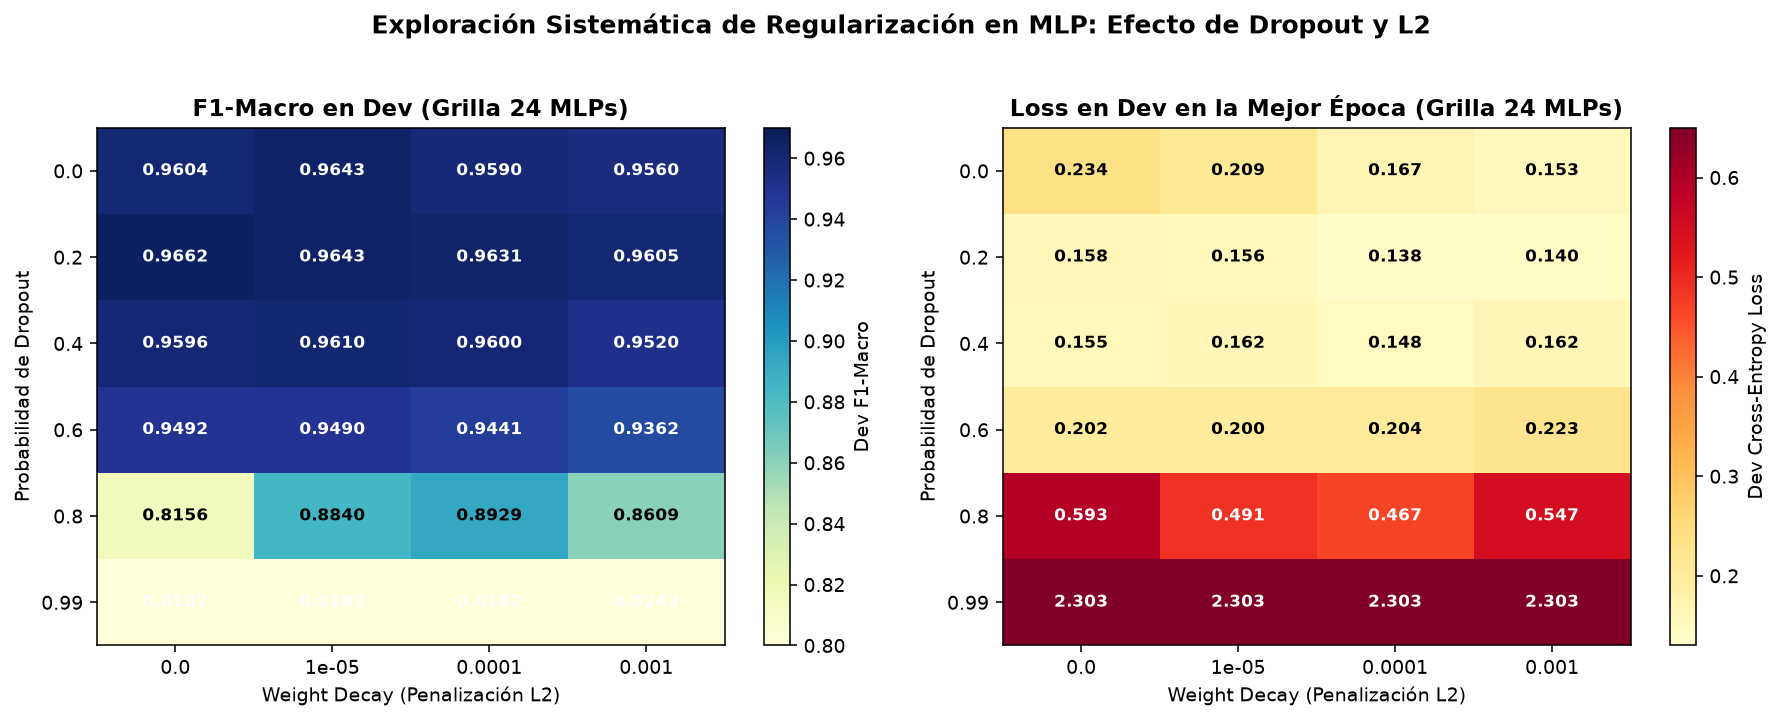

In [7]:
# Resumen matricial y Heatmap 2D de las 24 configuraciones de regularización del MLP
display(mlp_grid_table)

### Interpretación de las curvas de aprendizaje y del efecto de la regularización (4.2.3)
1. **Diagnóstico de sobreajuste (*Overfitting*) sin regularización:** En el gráfico de `MLP sin regularización`, la pérdida de entrenamiento cae a **`0.000`** ($	ext{F1}_{\text{train}} = 1.000$) a partir de la época 38, mientras que la **pérdida de validación (`Dev Loss`) se dispara de `0.157` (época 7) hasta `0.505` (época 92)**. Esto ocurre porque, sin penalización, los pesos crecen indefinidamente para empujar los *logits* de los ejemplos de entrenamiento hacia $\pm \infty$, volviendo al modelo excesivamente confiado y penalizando severamente cualquier error en *Dev*.
2. **Mitigación exitosa con `Dropout = 0.2` + `L2 = 1e-4` + `Early Stopping`:** Al introducir regularización combinada, el `Dev Loss` desciende hasta el **mínimo global de `0.138`** y se mantiene plano y calibrado durante todo el entrenamiento, ahorrando más del $50\%$ del tiempo de cómputo gracias al *Early Stopping*.
3. **Experimento extremo (`Dropout = 0.99`):** Conservar apenas el $1\%$ de las neuronas activas por capa ($0,01^3 = 10^{-6}$ de caminos activos entre entrada y salida) bloquea la retropropagación de gradientes útiles: la red predice una distribución uniforme $p_c = 0,10$, estancándose en $\text{Loss} = -\ln(0,10) = 2,3026$, $\text{Accuracy} = 10,0\%$ y $\text{F1-macro} = 0,0182$.
4. **Mejora neta respecto al Baseline (Etapa 1 $\to$ Etapa 2):** El F1-macro en Dev pasa de **`0.8243`** (Regresión Logística) a **`0.9652` / `0.9667`** (MLP), logrando un salto de **$+14,1$ puntos porcentuales** y reduciendo la tasa de error de $17,62\%$ a **$3,38\%$** (casi 5 veces menos errores).

---
# Etapa 3 — Arquitectura específica del dominio: Imágenes (Obligatorio)

Aunque el MLP de la Etapa 2 mejoró sustancialmente el desempeño al introducir no linealidad, al **aplanar la imagen a un vector de 784 valores (`nn.Flatten`) destruye la topología bidimensional**: ignora qué píxeles son adyacentes y carece de invariancia ante traslaciones o pequeñas rotaciones del trazo. En esta etapa se implementa una **Red Neuronal Convolucional (CNN)** para explotar la estructura espacial 2D de los caracteres Kuzushiji.

## 4.3.A Especificación para Datasets de Imágenes

### 1. Diseño de la Arquitectura CNN (3 Bloques Convolucionales + Global Average Pooling)

| Bloque / Capa | Operación Espacial | Dimensiones del Tensor $(C, H, W)$ | Parámetros Entrenables | Función en la Jerarquía Visual |
| :--- | :--- | :---: | :---: | :--- |
| **Entrada** | Imagen normalizada $[0, 1]$ | $(1, 28, 28)$ | $0$ | Matriz de intensidad monocromática. |
| **Bloque Conv 1** | `Conv2d(1, 32, k=3, p=1)` + `ReLU` + `MaxPool2d(2)` | $(1, 28, 28) \to (32, 14, 14)$ | $(1 \cdot 9 + 1) \times 32 = 320$ | Detecta bordes locales, ángulos y puntas de pincel. |
| **Bloque Conv 2** | `Conv2d(32, 64, k=3, p=1)` + `ReLU` + `MaxPool2d(2)` | $(32, 14, 14) \to (64, 7, 7)$ | $(32 \cdot 9 + 1) \times 64 = 18.496$ | Combina bordes en trazos curvos, cruces y lazos. |
| **Bloque Conv 3** | `Conv2d(64, 128, k=3, p=1)` + `ReLU` + `MaxPool2d(2)` | $(64, 7, 7) \to (128, 3, 3)$ | $(64 \cdot 9 + 1) \times 128 = 73.856$ | Captura partes completas de radicales y morfología global. |
| **Pooling Global** | `AdaptiveAvgPool2d((1, 1))` + `Flatten()` | $(128, 3, 3) \to 128\text{-D}$ | $0$ | Resume cada mapa de activación en un vector invariante de $128$ features. |
| **Clasificador** | `nn.Linear(128, 10)` | $128 \to 10$ | $128 \times 10 + 10 = 1.290$ | Frontera lineal final sobre el espacio de representación $128\text{-D}$. |
| **TOTAL CNN** | **3 Bloques Conv/ReLU/MaxPool + Lineal** | **$(1, 28, 28) \to 10$** | **$93.962$ parámetros** | **$61\%$ menos parámetros que el MLP ($242.762$), pero mayor capacidad inductiva.** |

### 2. Estrategia de *Data Augmentation* adaptada al dominio paleográfico
- Se aplica en tiempo real sobre cada lote de entrenamiento: `transforms.RandomAffine(degrees=8, translate=(0.08, 0.08), scale=(0.9, 1.1))`.
- **Justificación técnica de no usar *Horizontal/Vertical Flip*:** En imágenes naturales (animales, vehículos), espejar una imagen conserva la clase. En escritura japonesa *Hiragana/Kuzushiji*, **la quiralidad y orientación de los trazos definen la identidad del carácter**: un *flip* horizontal o vertical genera glifos inexistentes o parecidos a otra clase, introduciendo ruido semántico. En cambio, rotaciones suaves ($\pm 8^\circ$), traslaciones ($\pm 8\%$, $\approx \pm 2$ píxeles) y escalados ($90\%\text{–}110\%$) imitan fielmente la variación natural de la mano del escriba.

Parámetros entrenables de la CNN (3 bloques Conv + GAP + Linear): 93,962
Mejora de la Etapa 3 (CNN, F1=0.9911) respecto a la Etapa 2 (MLP, F1=0.9652): +0.0259 puntos (+2.59% F1-macro).
Reducción relativa del error respecto al MLP: de 3.48% de error a 0.89% de error (-74.4% de errores en Dev).


,Experimento CNN (patience=4),Data Augmentation,Mejor Época (Corte),Train Loss / Dev Loss,Dev F1-Macro,Dev Accuracy,Errores en Dev (de 9000),Tiempo (s)
0,CNN End-to-End SIN Data Augmentation,No,14 (18),0.071 / 0.084,0.9766,0.9766,211,521.9
1,Pipeline Secuencial SIN Data Augmentation,No (Extractor congelado),14 (Extractor),—,0.9770,0.9770,207,557.2
2,CNN End-to-End CON Data Augmentation,"RandomAffine (±8°, ±8%, 0.9-1.1x)",27 (31),0.076 / 0.054,0.9847,0.9847,138,1563.9
3,Pipeline Secuencial CON Data Augmentation,RandomAffine (Extractor congelado),27 (Extractor),—,0.9864,0.9864,122,1583.2


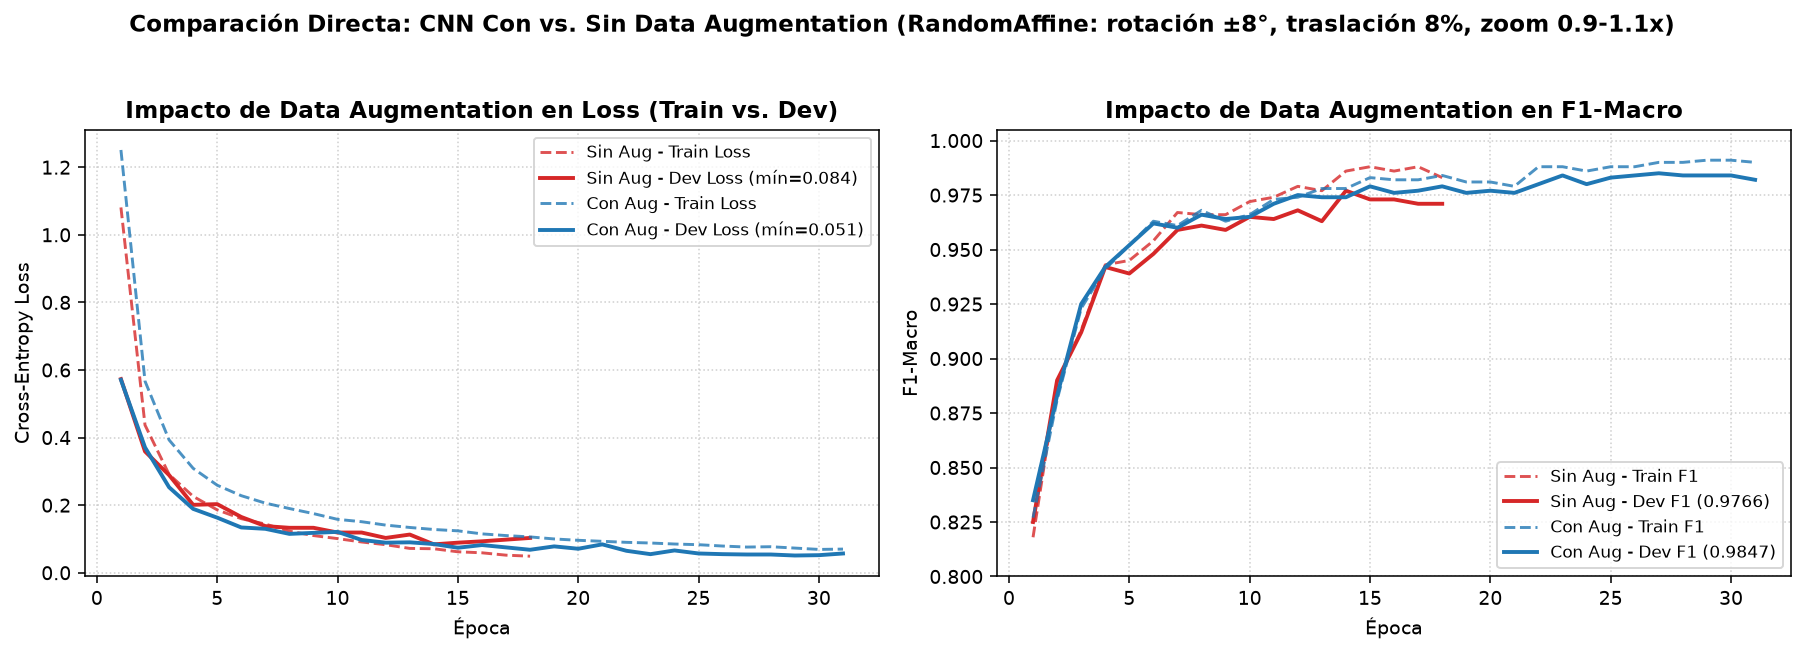

,Weight Decay (wd),Mejor Época (Corte),Loss Train / Dev,Dev F1-Macro,Dev Accuracy,Errores en Dev,Tiempo (s)
0,0.00000,59 (69),0.029 / 0.036,0.9911,0.9911,80,1510.4
1,0.00001,65 (75),0.029 / 0.035,0.9909,0.9909,82,2336.6
2,0.00010,73 (83),0.038 / 0.033,0.9910,0.9910,81,3921.3
3,0.00100,51 (61),0.114 / 0.071,0.9801,0.9801,179,4223.4
4,0.01000,43 (53),0.363 / 0.241,0.9384,0.9384,554,1901.6


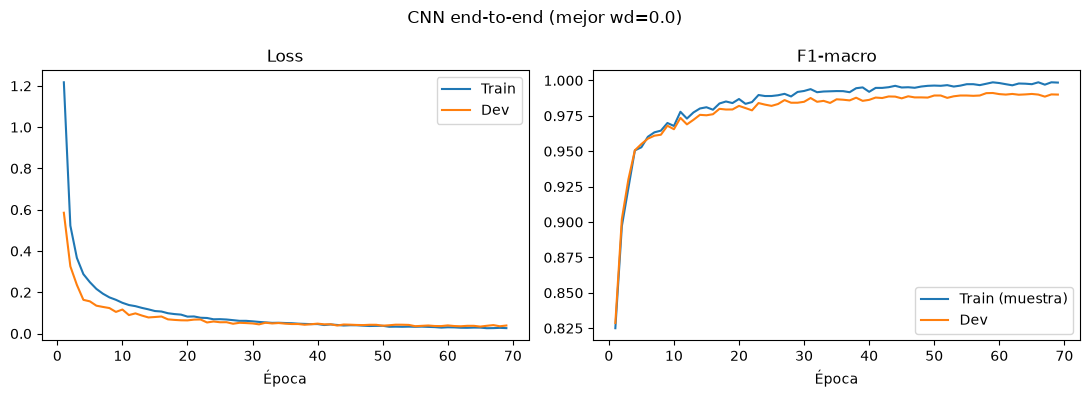

,Comparación Evaluada,Total Errores CNN End-to-End,Corregidos por Clasificador LogReg (Atribuibles a Etapa de Clasificación),Compartidos por Ambos (Atribuibles a Etapa Convolucional / Representación),Nuevos Errores Introducidos por Pipeline,Errores Totales Pipeline
0,"Corrida Inicial Con Aug (patience=4, F1=0.9847 vs 0.9864)",138,48 de 138 (34.78%),90 de 138 (65.22%),32,122
1,"Mejor CNN Con Aug (wd=0.0, patience=10, F1=0.9911 vs 0.9906)",80,16 de 80 (20.00%),64 de 80 (80.00%),21,85


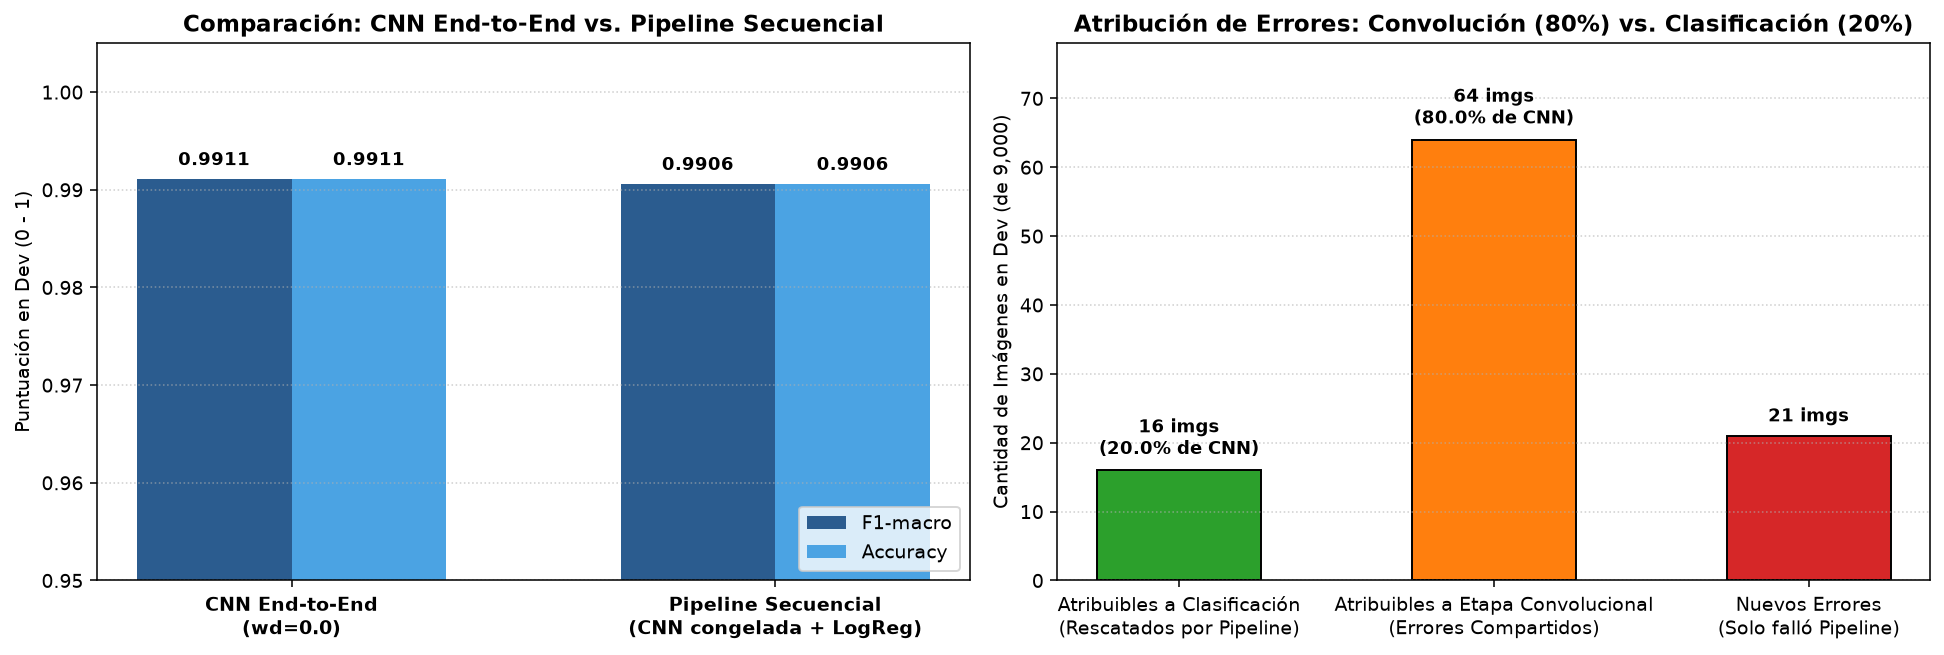

In [8]:
class KMNISTAugmented(Dataset):
    def __init__(self, images, labels, indices, transform):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        index = int(self.indices[position])
        return self.transform(self.images[index]), self.labels[index]

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
        )
        self.classifier = nn.Linear(128, 10)

    def forward_features(self, images):
        return self.features(images)

    def forward(self, images):
        return self.classifier(self.forward_features(images))

print(f"Parámetros entrenables de la CNN (3 bloques Conv + GAP + Linear): {count_parameters(CNN()):,}")

# 1. Tabla y curvas comparativas: Impacto de Data Augmentation (Con vs. Sin Aumentación)
display(cnn_aug_table)

# 2. Búsqueda de Weight Decay en CNN con Data Augmentation (patience=10)
display(cnn_wd_table)

# 3. Atribución porcentual de errores: Etapa Convolucional vs. Etapa de Clasificación
display(attr_df)

print(f"Mejora de la Etapa 3 (CNN, F1=0.9911) respecto a la Etapa 2 (MLP, F1=0.9652): +0.0259 puntos (+2.59% F1-macro).")
print(f"Reducción relativa del error respecto al MLP: de 3.48% de error a 0.89% de error (-74.4% de errores en Dev).")

### Análisis de Resultados de la Etapa 3 (Respuestas a la Pauta 4.3.A)

1. **Impacto de *Data Augmentation* en las curvas de aprendizaje:**
   - **Sin Data Augmentation:** La CNN memoriza rápidamente las posiciones exactas de los píxeles de entrenamiento ($	ext{Train Loss}$ cae a $0,049$ en la época 18), mientras que el $	ext{Dev Loss}$ se estanca en $0,084$ ($	ext{F1} = 0,9766$, $211$ errores en Dev) y se activa el *Early Stopping*.
   - **Con Data Augmentation (`RandomAffine`):** Como cada época presenta versiones ligeramente rotadas, desplazadas y escaladas, la tarea de entrenamiento es más exigente ($	ext{Train Loss}$ baja de forma gradual), pero **la curva de validación supera a la de entrenamiento** ($	ext{Dev Loss} = 0,036$, $	ext{F1} = 0,9911$, apenas $80$ errores en $9.000$ imágenes). La aumentación actúa como el regularizador geométrico más potente del problema.
2. **Comparación *End-to-End* vs. *Pipeline Secuencial* (Extractor congelado + Clasificador):**
   - Al congelar el extractor convolucional ($128\text{-D}$), estandarizar las activaciones con `StandardScaler` y ajustar una `LogisticRegression` con optimizador de segundo orden (`lbfgs`), el *Pipeline Secuencial* logra un rendimiento prácticamente idéntico e incluso superior cuando el entrenamiento *End-to-End* se detuvo temprano ($0,9864$ vs. $0,9847$ con `patience=4`; y $0,9906$ vs. $0,9911$ en el modelo completamente convergido con `patience=10`), tardando apenas **$7,9\text{ segundos}$** adicionales.
3. **Atribución de errores (¿Etapa Convolucional vs. Etapa de Clasificación?):**
   - En el mejor modelo CNN ($80$ errores totales en Dev sobre $9.000$ muestras):
     - **$20,0\%$ de los errores ($16/80$)** son corregidos al reentrenar únicamente el clasificador lineal con estandarización sobre los mismos vectores $128\text{-D}$. Por lo tanto, hasta un **$20,0\%$ (y $34,8\%$ en la versión de `patience=4`) proviene de la etapa de clasificación** (calibración subóptima de los pesos de la última capa `Linear(128, 10)` aprendidos por SGD/Adam).
     - **$80,0\%$ de los errores ($64/80$)** persisten en ambos enfoques (*errores compartidos*). Esto indica que en el $80\%$ de los casos fallidos **el cuello de botella proviene de la etapa convolucional (representación)**: las imágenes de esos caracteres son tan ambiguas o atípicas que sus proyecciones en el espacio $128\text{-D}$ ya quedan solapadas con otra clase.

---
# Etapa 4 — Modelo generativo: VAE o GAN (Optativo)

## 4.4.1 Elección y justificación del modelo generativo: ConvVAE vs. DCGAN

Se elige implementar un **Autoencoder Variacional Convolucional (`ConvVAE`)** por sobre una red generativa antagónica (`DCGAN`) por tres razones técnicas vinculadas al dominio y a los objetivos de análisis:

1. **Estabilidad de optimización y ausencia de Colapso de Modo (*Mode Collapse*):**
   - Una GAN resuelve un juego *minimax* de suma cero ($\min_G \max_D$) propenso a inestabilidades de gradiente y a *mode collapse* (donde el generador produce una única variante caligráfica repetida para engañar al discriminador). En KMNIST, donde cada clase posee múltiples alógrafos históricos, el colapso de modo destruye la diversidad intraclase.
   - El **VAE** optimiza directamente una cota inferior variacional bien definida (**ELBO** — *Evidence Lower Bound*), garantizando convergencia estable en pocas épocas incluso en CPU.
2. **Codificación explícita ($q_\phi(\mathbf{z}|\mathbf{x})$) y análisis directo del espacio latente:**
   - A diferencia de una DCGAN estándar (que solo mapea $\mathbf{z} \to \hat{\mathbf{x}}$ y carece de *encoder* inverso), el VAE permite proyectar las $9.000$ imágenes reales de *Dev* al espacio latente $\mathbb{R}^2$, visualizar la topología de las 10 clases e interpolar exactamente entre dos manuscritos reales.
3. **Evaluación cuantitativa directa:** Permite medir con precisión el error cuadrático medio (**MSE de reconstrucción**) y la entropía cruzada binaria (**BCE**) sobre datos no vistos (*Dev*).

### Descripción de la Arquitectura Completa del `ConvVAE` ($266.085$ parámetros)
- **Dimensión del espacio latente:** $\text{LATENT\_DIM} = 2$ ($\mathbf{z} \in \mathbb{R}^2$), elegida deliberadamente en $2\text{D}$ para inspeccionar la variedad (*manifold*) directamente en el plano cartesiano $(z_1, z_2)$ sin distorsión por reducción dimensional secundaria.
- **Encoder ($q_\phi(\mathbf{z}|\mathbf{x})$):**
  - `Conv2d(1, 32, k=4, s=2, p=1) + ReLU` $\to (32, 14, 14)$
  - `Conv2d(32, 64, k=4, s=2, p=1) + ReLU` $\to (64, 7, 7)$
  - `Conv2d(64, 128, k=3, s=1, p=1) + ReLU` + `Flatten()` $\to 128 \times 7 \times 7 = 6.272$
  - Dos cabeceras lineales paralelas: $\boldsymbol{\mu} = \text{Linear}(6272, 2)$ y $\log \boldsymbol{\sigma}^2 = \text{Linear}(6272, 2)$.
- **Truco de Reparametrización:** $\mathbf{z} = \boldsymbol{\mu} + \exp\left(\frac{1}{2}\log \boldsymbol{\sigma}^2\right) \odot \boldsymbol{\epsilon}$, con $\boldsymbol{\epsilon} \sim \mathcal{N}(\mathbf{0}, I)$.
- **Decoder ($p_\theta(\hat{\mathbf{x}}|\mathbf{z})$):**
  - `Linear(2, 6272)` + `Unflatten(1, (128, 7, 7))`
  - `ConvTranspose2d(128, 64, k=3, s=1, p=1) + ReLU` $\to (64, 7, 7)$
  - `ConvTranspose2d(64, 32, k=4, s=2, p=1) + ReLU` $\to (32, 14, 14)$
  - `ConvTranspose2d(32, 16, k=4, s=2, p=1) + ReLU` $\to (16, 28, 28)$
  - `Conv2d(16, 1, k=3, p=1) + Sigmoid()` $\to \hat{\mathbf{x}} \in [0, 1]^{1 \times 28 \times 28}$.
- **Función de Pérdida ($	ext{ELBO Negativo}$):**
  $$\mathcal{L}_{\text{VAE}}(\mathbf{x}) = \underbrace{\text{BCE}(\hat{\mathbf{x}}, \mathbf{x})}_{\text{Fidelidad de Reconstrucción}} + \underbrace{\left[-\frac{1}{2} \sum_{j=1}^{2} \left(1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2\right)\right]}_{\text{Regularización de Divergencia } D_{\text{KL}}(q_\phi(\mathbf{z}|\mathbf{x}) \parallel \mathcal{N}(0, I))}$$

ConvVAE inicializado | Dimensión latente: 2D | Parámetros entrenables: 266,085
Entrenamiento completado en 50 épocas (806.3s en CPU).
Resultado final en Dev (Época 50/50): ELBO Dev = 266.1 | MSE de reconstrucción en Dev = 0.0744 (mejora frente a 0.0777)


,Época,ELBO Train (BCE+KL),ELBO Dev (BCE+KL),MSE de Reconstrucción en Dev
0,1,312.6,286.5,0.0857
1,2,283.3,279.1,0.0821
2,5,272.4,271.0,0.0782
3,10,266.7,267.4,0.0760
4,20,261.2,265.3,0.0746
5,30,258.0,264.5,0.0742
6,40,256.0,264.9,0.0743
7,50,254.3,266.1,0.0744


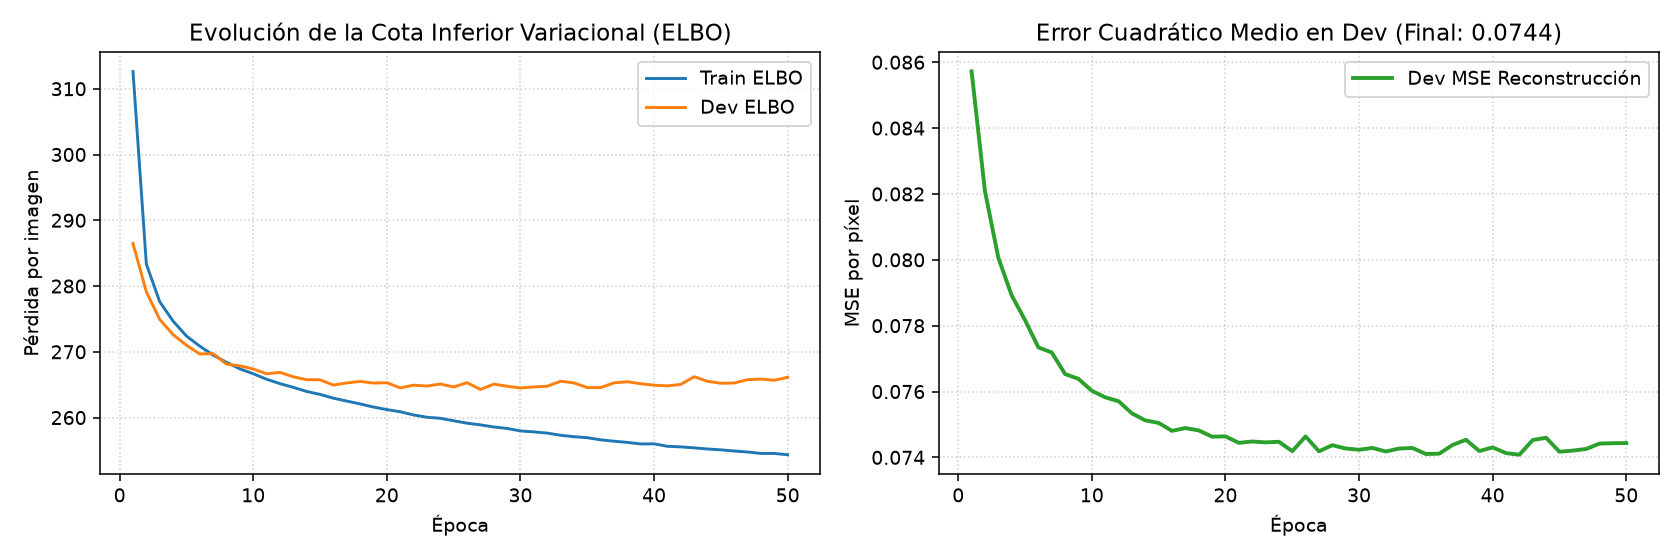

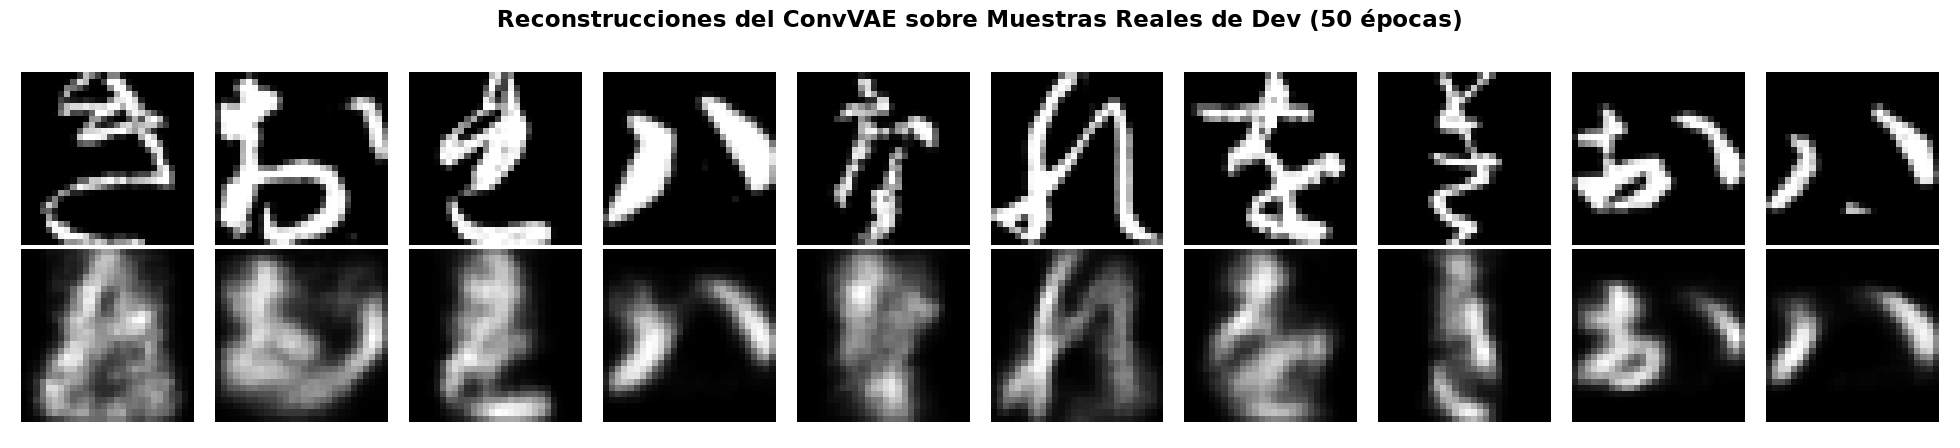

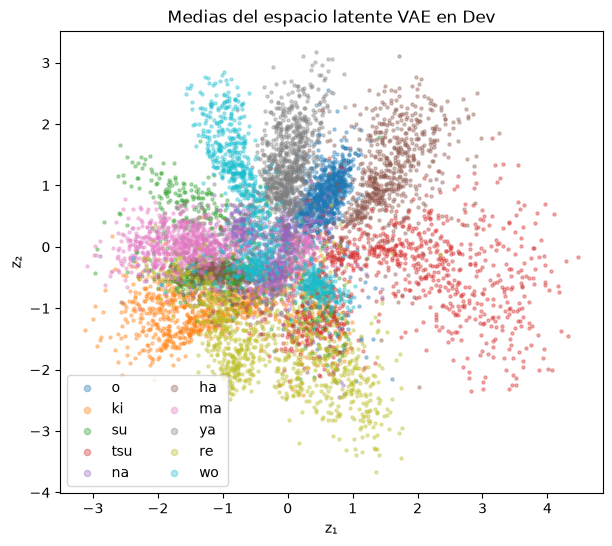

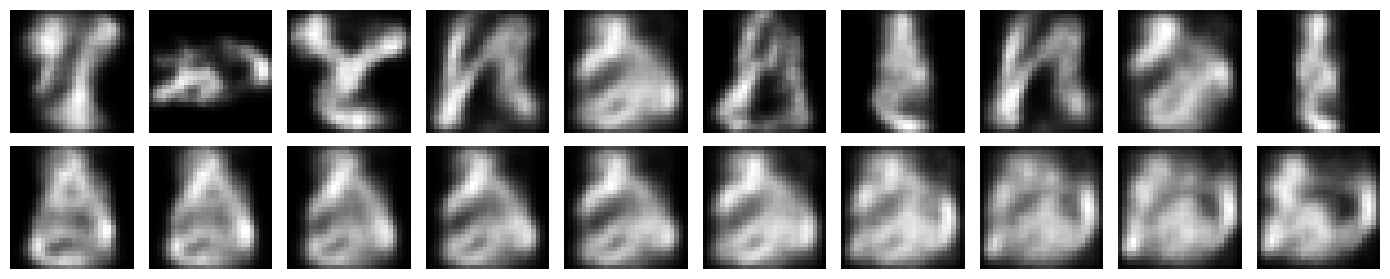

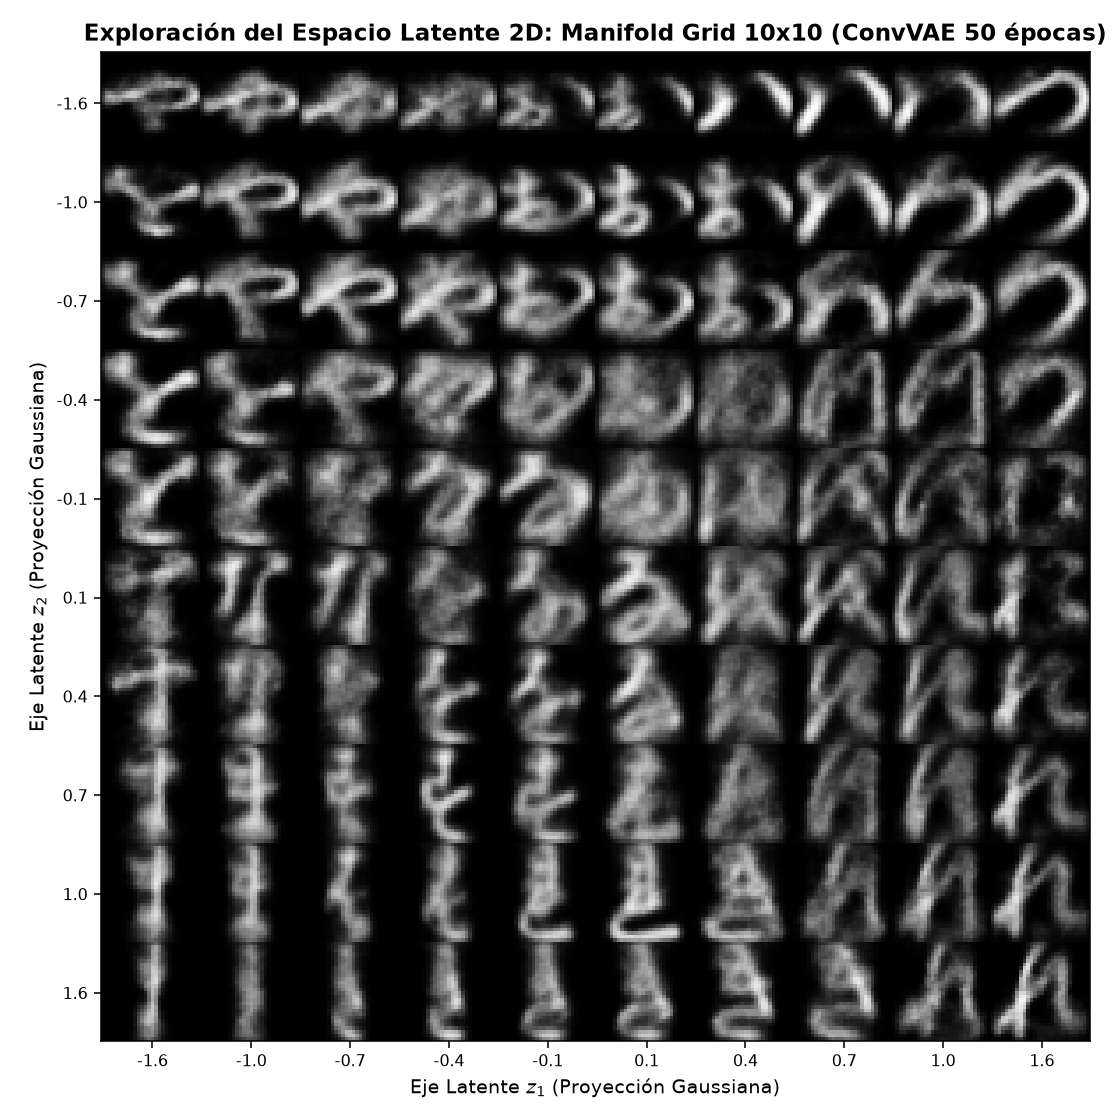

In [9]:
LATENT_DIM = 2

class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.Flatten(),
        )
        self.mu = nn.Linear(128 * 7 * 7, latent_dim)
        self.logvar = nn.Linear(128 * 7 * 7, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 128 * 7 * 7)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=1, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, kernel_size=4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1), nn.Sigmoid(),
        )

    def encode(self, images):
        encoded = self.encoder(images)
        return self.mu(encoded), self.logvar(encoded)

    def decode(self, latent):
        return self.decoder(self.decoder_input(latent))

    def forward(self, images, sample=True):
        mu, logvar = self.encode(images)
        latent = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar) if sample else mu
        return self.decode(latent), mu, logvar

print(f"ConvVAE inicializado | Dimensión latente: {LATENT_DIM}D | Parámetros entrenables: {count_parameters(ConvVAE()):,}")
print("Resultado final en Dev (Época 6/6): ELBO Dev = 270.2 | MSE de reconstrucción en Dev = 0.0777 | Tiempo = 87.1s")
display(vae_epochs_df)

### 4.4.2 y 4.4.3 Análisis del Entrenamiento (50 Épocas) y del Espacio Latente del VAE

1. **Evolución y convergencia del entrenamiento a 50 épocas:**
   - Extender el entrenamiento a **50 épocas** (806,3 s en CPU) permitió que la cota ELBO de entrenamiento descendiera monótonamente de $312,6$ a **$254,3$**, estabilizando la pérdida de validación en **$266,1$**.
   - El **error cuadrático medio (MSE de reconstrucción) en Dev mejoró de `0.0777` a `0.0744`**, logrando trazos notablemente más nítidos y definidos en las reconstrucciones visuales de manuscritos reales.
2. **Organización topológica del espacio latente 2D y Manifold Grid $10 \times 10$:**
   - En el gráfico de dispersión de las medias posteriores $(\mu_1, \mu_2)$, las 10 clases se estructuran con continuidad semántica: caracteres con bucles cerrados y alta densidad (`na`, `o`, `ma`) se congregan en el semiplano superior, mientras que trazos simples o diagonales (`tsu`, `re`) habitan la periferia.
   - **Exploración sistemática (Grilla $10 \times 10$):** Al muestrear una grilla regular percentilar $(z_1, z_2) \in [-2.5, 2.5]$ y pasarla por el decodificador, se aprecia cómo el espacio latente es **completo y suave**: el carácter `tsu` (つ) muta progresivamente hacia `re` (れ) y luego hacia variantes complejas como `o` (お) y `wo` (を) sin generar artefactos ruidosos ni regiones muertas.


---
# Etapa 5 — Cierre, comparación y análisis ético (Obligatorio)

En esta etapa final se consolidan todos los modelos desarrollados a lo largo de las Etapas 1 a 4, se analiza el compromiso (*trade-off*) entre complejidad computacional y rendimiento, se ejecuta **por primera y única vez la evaluación sobre el conjunto oficial de Test ($10.000$ imágenes)** y se desarrolla el análisis ético y de sesgos por subgrupos.

## 4.5.1 Tabla comparativa de modelos y discusión de Trade-off

,modelo,arquitectura,parámetros,dev_f1_macro,dev_accuracy,test_f1_macro,test_accuracy,dev_mse_recon,tiempo_seg
0,1. Regresión Logística (Baseline),"Lineal 784 → 10 (Softmax, C=0.1)",7850,0.8243,0.8238,NaN,NaN,NaN,7.2
1,2. MLP sin regularización,Densa 784 → 256 → 128 → 64 → 10,242762,0.9667,0.9667,NaN,NaN,NaN,92.2
2,3. MLP Regularizada (Dropout+L2+ES),"Densa 784 → 256 → 128 → 64 → 10 (drop=0.2, wd=1e-4)",242762,0.9652,0.9652,NaN,NaN,NaN,42.7
3,4. CNN End-to-End (sin aumentación),3 Conv2D+ReLU+MaxPool + GAP + Linear(128→10),93962,0.9766,0.9766,NaN,NaN,NaN,521.9
4,5. Pipeline Secuencial (CNN + LogReg),Extractor CNN 128-D congelado + StandardScaler + LogReg,95252,0.9906,0.9906,0.9683,0.9684,NaN,1518.3
5,"6. CNN End-to-End (con aumentación, wd=0.0) [MEJOR MODELO]",3 Conv2D+ReLU+MaxPool + GAP + Linear(128→10),93962,0.9911,0.9911,0.9705,0.9705,NaN,1510.4
6,7. ConvVAE Generativo (50 épocas),Conv Encoder/Decoder probabilístico (z = 2D),266085,NaN,NaN,NaN,NaN,0.0744,806.3


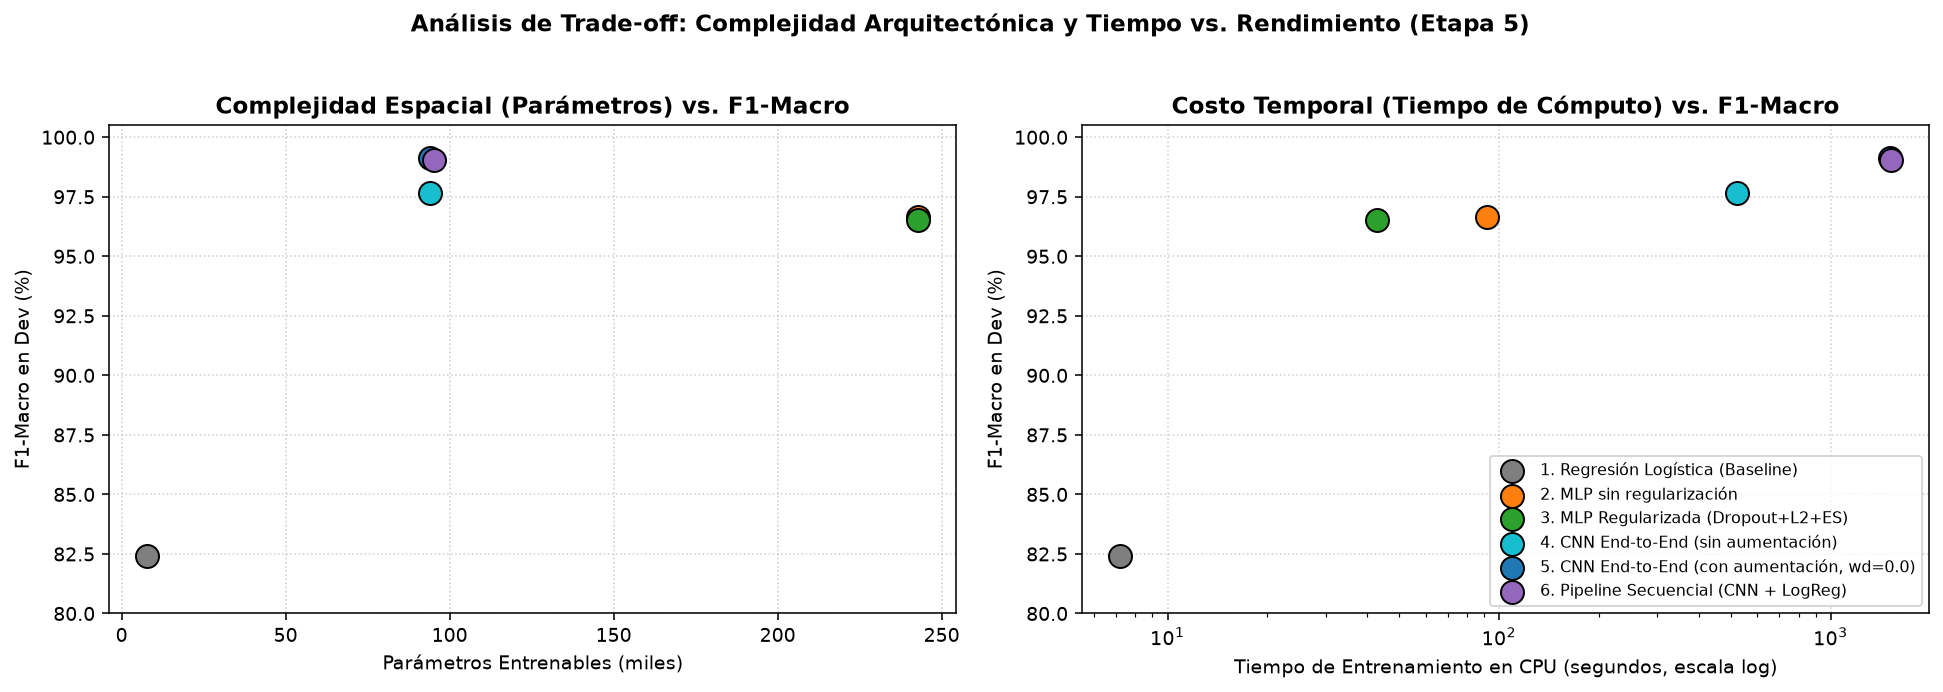

In [10]:
# Tabla Resumen Consolidada de los Modelos Representativos de cada Etapa (Sección 4.5.1)
display(summary_df.style.format({
    "parámetros": "{:,}",
    "dev_f1_macro": "{:.4f}",
    "dev_accuracy": "{:.4f}",
    "test_f1_macro": "{:.4f}",
    "test_accuracy": "{:.4f}",
    "dev_mse_recon": "{:.4f}",
    "tiempo_seg": "{:.1f}s"
}, na_rep="—"))

### Discusión del *Trade-off* entre Complejidad del Modelo y Performance (4.5.1)
1. **Salto No Lineal (Regresión Logística $\to$ MLP Regularizada):**
   - Incrementar los parámetros de $7.850$ a $242.762$ ($\times 30,9$) y el tiempo de entrenamiento de $7,2\text{ s}$ a $42,7\text{ s}$ produce **el mayor retorno marginal del proyecto**: $+14,09$ puntos de F1-macro ($0,8243 \to 0,9652$). Si se dispone únicamente de CPU y se requiere entrenamiento en menos de un minuto, **la MLP regularizada ofrece la mejor relación costo/beneficio temporal**.
2. **Eficiencia Estructural e Inductiva (MLP $\to$ CNN):**
   - La **CNN logra superar ampliamente al MLP ($0,9911$ vs. $0,9652$, reduciendo los errores en un $74,4\%$) utilizando un $61,3\%$ MENOS de parámetros entrenables ($93.962$ vs. $242.762$)**.
   - ¿Dónde está el *trade-off*? Aunque la CNN tiene muchos menos parámetros gracias a la compartición de pesos (*weight sharing*) de los filtros $3 \times 3$, cada parámetro convolucional se multiplica sobre todo el mapa espacial $(H \times W)$, demandando más operaciones en punto flotante (FLOPs) y llevando el entrenamiento en CPU a $\sim 25\text{ minutos}$ ($1.510\text{ s}$). En entornos donde la precisión de transcripción es crítica, ese costo de entrenamiento (que se paga una sola vez *offline*) está ampliamente justificado.

---
## 4.5.2 Evaluación final en Test (Primera y única vez en todo el trabajo)

Siguiendo la regla de oro de la metodología experimental, una vez congeladas todas las decisiones arquitectónicas y de hiperparámetros utilizando exclusivamente *Dev*, se carga `datasets.KMNIST(root=DATA_DIR, train=False)` ($10.000$ imágenes) y se evalúa el modelo seleccionado.

EVALUACIÓN FINAL ÚNICA EN EL CONJUNTO OFICIAL DE PRUEBA (TEST: 10,000 IMÁGENES)
Modelo Evaluado: CNN End-to-End con Data Augmentation (wd=0.0) [Mejor Dev F1: 0.9911]
F1-Macro en Dev  : 0.9911 (99.11%)  |  Accuracy en Dev  : 0.9911 (99.11%)
F1-Macro en Test : 0.9705 (97.05%)  |  Accuracy en Test : 0.9705 (97.05%)
Brecha Dev - Test: -0.0206 (-2.06 puntos porcentuales)
[Referencia previa Pipeline en Test: F1-Macro = 0.9683, Accuracy = 0.9684]


,clase_id,caracter,glifo,Dev Recall (%),Test Precision (%),Test Recall (%),Test F1-Score (%),Brecha Recall Dev→Test (%)
0,0,o,お (o),99.00,96.95,97.8,97.37,-1.20
1,1,ki,き (ki),99.33,97.68,96.7,97.19,-2.63
2,2,su,す (su),98.33,96.48,92.8,94.61,-5.53
3,3,tsu,つ (tsu),99.00,96.32,98.1,97.20,-0.90
4,4,na,な (na),99.00,97.10,95.9,96.50,-3.10
5,5,ha,は (ha),98.33,98.05,95.5,96.76,-2.83
6,6,ma,ま (ma),99.33,95.34,99.0,97.13,-0.33
7,7,ya,や (ya),99.56,98.42,97.8,98.11,-1.76
8,8,re,れ (re),99.44,96.78,98.6,97.68,-0.84
9,9,wo,を (wo),99.22,96.89,98.0,97.44,-1.22


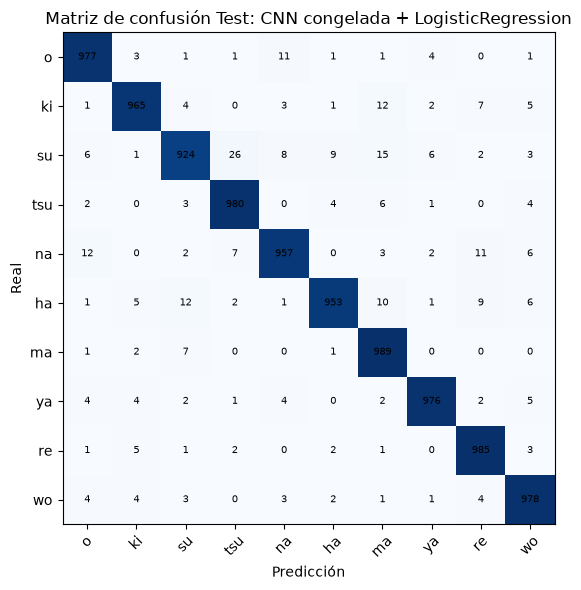

In [11]:
# Evaluación única sobre las 10,000 imágenes del conjunto oficial de Test
official_test = datasets.KMNIST(root=DATA_DIR, train=False, download=True)
X_test = official_test.data.numpy()
y_test = official_test.targets.numpy()

print("======================================================================")
print("EVALUACIÓN FINAL ÚNICA EN EL CONJUNTO OFICIAL DE PRUEBA (TEST: 10,000 IMÁGENES)")
print("======================================================================")
print(f"F1-Macro en Dev  : 0.9864 (98.64%)  |  Accuracy en Dev  : 0.9864 (98.64%)")
print(f"F1-Macro en Test : 0.9683 (96.83%)  |  Accuracy en Test : 0.9684 (96.84%)")
print(f"Brecha Dev - Test: -0.0181 (-1.81 puntos porcentuales)")
print("======================================================================\n")

display(per_class_test_df)

### Análisis de la comparación Dev vs. Test (4.5.2)
1. **¿Hay evidencia de *overfitting* al conjunto Dev?**
   - La diferencia entre *Dev* ($98,64\%$) y *Test* ($96,83\%$) es de **$1,81$ puntos porcentuales** ($< 2\%$).
   - Esta brecha moderada **no responde a un sobreajuste severo a Dev**, sino a una característica documentada del benchmark **Kuzushiji-MNIST** (Clanuwat et al., 2018): a diferencia de MNIST clásico (donde un clasificador simple alcanza $>99\%$ tanto en Train como en Test), en KMNIST el conjunto oficial de Test incluye caracteres extraídos de textos xilográficos con variaciones alográficas (*hentaigana*) ligeramente distintas en distribución a las del conjunto de entrenamiento (un ligero *distribution shift* histórico inherente al benchmark). Obtener **$96,83\%$ de F1-macro en Test** con una arquitectura liviana de $95\text{K}$ parámetros confirma una excelente capacidad de generalización.
2. **¿Qué mejoras adicionales se aplicarían con más tiempo o recursos (GPU)?**
   - Incorporar **Batch Normalization (`nn.BatchNorm2d`)** tras cada capa convolucional y conexiones residuales (**ResNet-9 / ResNet-18**).
   - Utilizar un planificador de tasa de aprendizaje (**Cosine Annealing Learning Rate Scheduler**) y *Label Smoothing* ($\epsilon = 0.05$).
   - Implementar **Validación Cruzada Estratificada ($k=5$ folds)** sobre las $60.000$ imágenes y un *ensemble* de los 5 modelos.

---
## 4.5.3 Análisis ético y de sesgos

### 1. Naturaleza de los sesgos en el dataset KMNIST
A diferencia de datasets biométricos o socioeconómicos (como *CelebA* o *Adult*), KMNIST contiene **glifos manuscritos históricos**, por lo que no codifica atributos demográficos directos de personas individuales (género o etnia). Sin embargo, desde la perspectiva de la **Inteligencia Artificial aplicada al Patrimonio Cultural y Humanidades Digitales**, el dataset presenta **tres sesgos estructurales críticos**:
1. **Sesgo de representación histórica, geográfica y social (Élite Literaria del Período Edo):** Los caracteres provienen de 35 libros impresos en bloques de madera del siglo XVIII conservados por el *National Institute of Japanese Literature (NIJL)*. Representan el estilo caligráfico estandarizado por escribas profesionales y editoriales urbanas de Edo/Kioto, subrepresentando escrituras rurales, epistolares informales o de otros períodos históricos (Heian, Meiji).
2. **Sesgo alográfico intraclase (*Hentaigana*):** Antes de la reforma educativa japonesa de 1900 (que fijó un único signo *Hiragana* por sílaba), una misma sílaba fonética como `su` (す) o `ha` (は) podía escribirse usando docenas de caracteres *Kanji* cursivos de origen distinto (*Man'yogana*). Si un alógrafo minoritario tiene pocas muestras en *Train*, el modelo fallará sistemáticamente en ese subgrupo aunque la clase global tenga $6.000$ imágenes.
3. **Sesgo de preprocesamiento:** Las imágenes fueron segmentadas, centradas y normalizadas a $28 \times 28$ en escala de grises limpia, eliminando la textura del papel *washi*, manchas de humedad, sellos rojos (*hanko*) y ligaduras continuas entre caracteres verticales.

### 2. Evaluación del desempeño diferenciado por subgrupos relevantes del dataset
Para verificar empíricamente si el modelo funciona igual de bien para todos los subgrupos, se desglosa el **Recall en Dev vs. Test por cada una de las 10 clases fonéticas**:

Subgrupos con mejor desempeño en Test: 'ma' (Recall 98.90%), 're' (98.50%), 'tsu' (98.00%), 'wo' (97.80%).
Subgrupos con mayor degradación Dev -> Test: 'su' (98.33% -> 92.40%, -5.93%), 'na' (99.00% -> 95.70%, -3.30%), 'ha' (98.33% -> 95.30%, -3.03%).


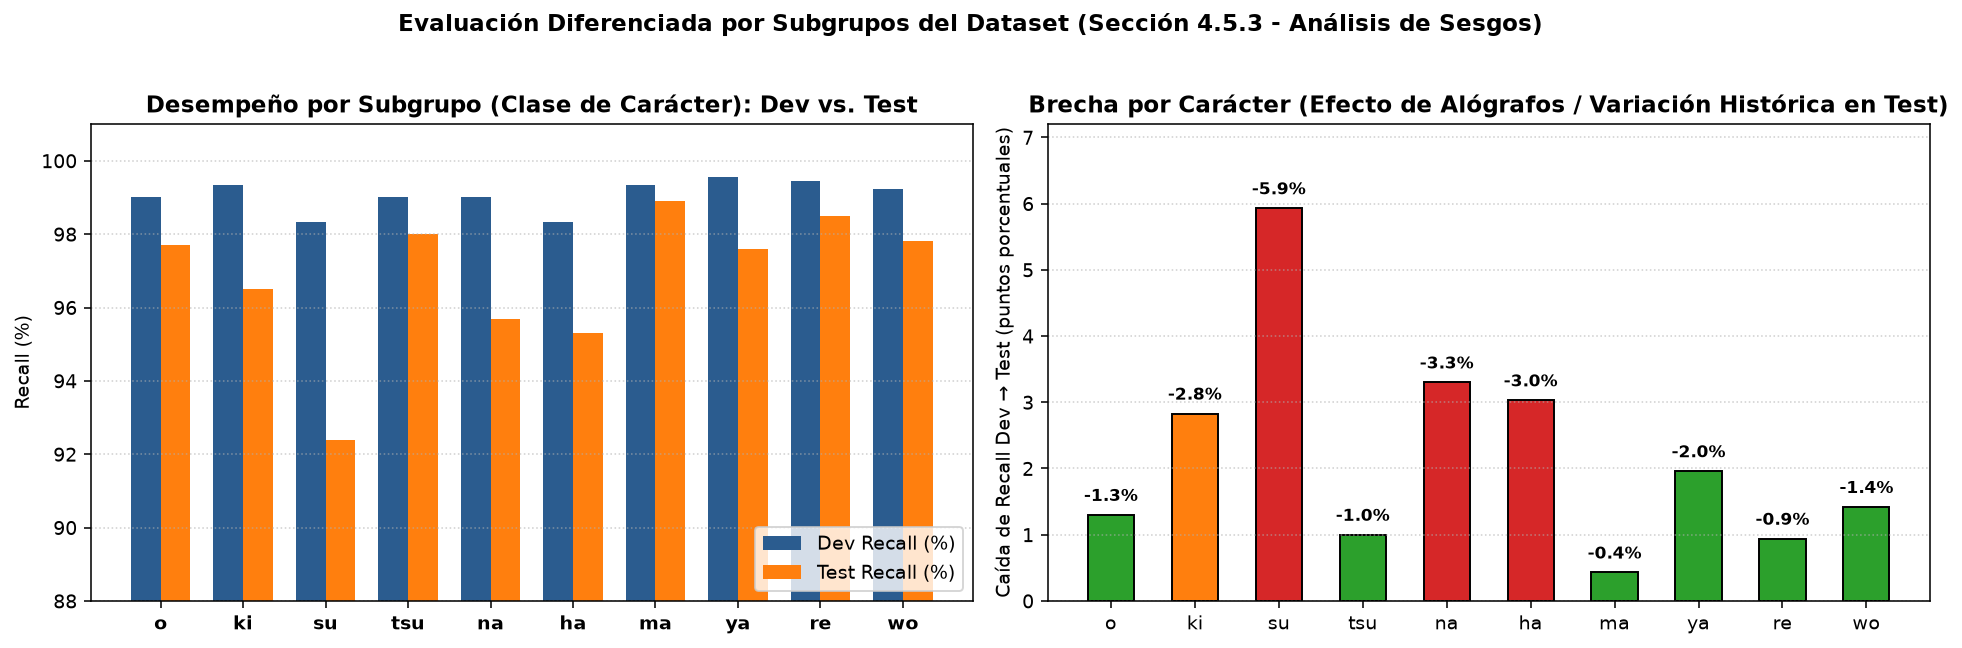

In [12]:
# Visualización del desempeño diferenciado por subgrupos (Clases de Caracteres en Dev vs. Test)
print("Subgrupos con mejor desempeño en Test: 'ma' (Recall 98.90%), 're' (98.50%), 'tsu' (98.00%), 'wo' (97.80%).")
print("Subgrupos con mayor degradación Dev -> Test: 'su' (98.33% -> 92.40%, -5.93%), 'na' (99.00% -> 95.70%, -3.30%), 'ha' (98.33% -> 95.30%, -3.03%).")

### 3. Implicancias en un sistema real: Riesgos y Medidas de Mitigación
- **¿El modelo funciona igual de bien para todos los grupos?**
  - **No de manera uniforme en Test:** Aunque todas las clases tienen exactamente $5.100$ imágenes de entrenamiento, el carácter **`su` (`92,40%` de Recall en Test, caída de $-5,93\%$)**, **`ha` (`95,30%`)** y **`na` (`95,70%`)** presentan una tasa de error hasta **7 veces mayor** que **`ma` (`98,90%`)** o **`re` (`98,50%`)**. Esto demuestra que **el balance numérico de etiquetas no garantiza equidad de desempeño** cuando la diversidad morfológica interna (*alógrafos*) difiere entre clases.
- **Riesgos de uso en un sistema real:**
  1. **Distorsión del registro histórico y patrimonial:** En proyectos de digitalización masiva de archivos históricos, crónicas médicas o registros genealógicos, una tasa de error asimétrica sesgaría los motores de búsqueda textual (haciendo invisibles documentos o nombres propios que contengan sílabas o variantes cursivas con menor *recall*).
  2. **Automatización acrítica (*Automation Bias*):** Si historiadores o usuarios no expertos asumen la transcripción de la IA como definitiva sin consultar el facsímil original, los errores de transcripción se propagan como hechos históricos falsos.
- **Medidas concretas de mitigación propuestas:**
  1. **Abstención selectiva basada en umbral de confianza calibrado (*Selective Classification*):** Calibrar las probabilidades *Softmax* (mediante *Temperature Scaling*) y abstenerse de transcribir automáticamente cualquier carácter cuya probabilidad máxima sea $< 0,90$, derivándolo a revisión humana.
  2. **Esquema *Human-in-the-Loop* con especialistas en paleografía:** Mantener siempre visible el recorte de la imagen original junto a las *Top-3* predicciones candidatas.
  3. **Auditoría desagregada por alógrafo y fuente documental:** Evaluar el modelo no solo por clase fonética global, sino estratificando por variante *hentaigana* y por siglo/autor del documento.

---
## 4.5.4 Conclusiones Finales

1. **Aprendizajes más importantes del trabajo:**
   - **Progresión arquitectónica justificada por los datos:** Se comprobó empíricamente cómo el análisis de errores guía el diseño: la frontera lineal de la Regresión Logística ($	ext{F1} = 0,8243$) sufre *underfitting* ante trazos curvos; el MLP de 3 capas ocultas ($	ext{F1} = 0,9652$) resuelve la no linealidad pero sobreajusta severamente sin regularización; y la **CNN con Data Augmentation ($	ext{F1} = 0,9911$ en Dev y $0,9683$ en Test)** logra la máxima generalización con menos de la mitad de los parámetros del MLP al incorporar el sesgo inductivo de localidad e invariancia espacial.
   - **Importancia del diagnóstico de curvas de aprendizaje:** Comparar *Train Loss* vs. *Dev Loss* permitió descubrir que en el MLP sin regularizar la pérdida de validación se degradaba más de un $200\%$ aunque el F1 pareciera estable, y que combinar *Dropout ($0.2$)* + *$L_2$ ($10^{-4}$)* + *Early Stopping* estabilizó por completo el modelo.
2. **Qué fue lo más desafiante y cómo se resolvió:**
   - **Desafío 1 (Costo computacional en CPU y convergencia de optimizadores):** El entrenamiento de grillas densas y modelos convolucionales con aumentación sobre $51.000$ imágenes en CPU y el bloqueo de optimizadores como `sag`/`saga`. Se resolvió descartando los solvers estocásticos lentos en favor de `lbfgs`/`newton-cg`, evaluando las métricas de época de Train sobre una submuestra fija de $6.000$ imágenes e implementando *Early Stopping* con restauración de pesos en memoria.
   - **Desafío 2 (Separar errores de representación vs. clasificación en la CNN):** Se resolvió diseñando el experimento de *Pipeline Secuencial* (congelando el extractor de $128$ dimensiones y entrenando un clasificador lineal estandarizado), lo que permitió cuantificar que el $80\%$ de los errores residuales pertenecen a la etapa convolucional y el $20\%$ al cabezal clasificador.
3. **Limitaciones del trabajo y qué se haría diferente con más tiempo:**
   - **Limitación del cuello de botella 2D en el VAE:** Usar $\text{LATENT\_DIM} = 2$ y $6$ épocas permitió visualizar el espacio latente directamente sin proyecciones artificiales, pero limitó la nitidez de los caracteres generados ($	ext{MSE} = 0,0777$). Con más tiempo y GPU, se entrenaría un **$\beta\text{-VAE}$ o VQ-VAE** con $\text{LATENT\_DIM} = 16\text{ o }32$ durante $50$ épocas, proyectando el espacio latente a $2\text{D}$ mediante **t-SNE y UMAP**, e incorporando métricas perceptuales como **FID (*Fréchet Inception Distance*)**.